In [4]:
# def generate_weather_data(year=2023, seed=42):
#     """
#     Generate NYC-calibrated daily weather data for one full year.
#     Based on NOAA Central Park climatological normals.
#     """
#     rng = np.random.default_rng(seed)
#     dates = pd.date_range(f'{year}-01-01', f'{year}-12-31', freq='D')
#     n = len(dates)
#     doy = np.arange(1, n + 1)   # day of year

#     # ── Temperature (°C) ────────────────────────────────────────
#     # NYC mean: ~3°C in Jan, ~25°C in Jul → amplitude ≈ 11, mean ≈ 13
#     temp_seasonal = 13 + 11 * np.sin(2 * np.pi * (doy - 80) / 365)

#     # AR(1) noise with persistence = 0.7 (weather memory)
#     ar_noise = np.zeros(n)
#     ar_noise[0] = rng.normal(0, 3)
#     for i in range(1, n):
#         ar_noise[i] = 0.72 * ar_noise[i-1] + rng.normal(0, 2.2)

#     temp_mean = temp_seasonal + ar_noise

#     # Diurnal range: larger in summer, smaller in winter
#     diurnal = 5 + 3 * np.sin(2 * np.pi * (doy - 80) / 365)
#     temp_max = temp_mean + diurnal / 2 + rng.normal(0, 0.8, n)
#     temp_min = temp_mean - diurnal / 2 + rng.normal(0, 0.8, n)

#     # ── Humidity (%) ─────────────────────────────────────────────
#     # Higher in summer, lower in winter; anti-correlated with temp
#     humidity = 60 + 8 * np.sin(2 * np.pi * (doy - 160) / 365)
#     humidity += -0.3 * ar_noise + rng.normal(0, 5, n)
#     humidity = np.clip(humidity, 20, 100)

#     # ── Pressure (hPa) ───────────────────────────────────────────
#     # Higher in winter (cold highs), lower in summer
#     pressure_seasonal = 1013 + 5 * np.cos(2 * np.pi * (doy - 10) / 365)
#     press_noise = np.zeros(n)
#     press_noise[0] = rng.normal(0, 3)
#     for i in range(1, n):
#         press_noise[i] = 0.65 * press_noise[i-1] + rng.normal(0, 2.5)
#     pressure = pressure_seasonal + press_noise

#     # ── Wind Speed (km/h) ────────────────────────────────────────
#     # Windier in winter/spring
#     wind_seasonal = 14 + 4 * np.cos(2 * np.pi * (doy - 40) / 365)
#     wind = wind_seasonal + np.abs(rng.normal(0, 4, n))
#     wind = np.clip(wind, 0, 60)

#     # ── Precipitation (mm) ───────────────────────────────────────
#     # NYC has relatively uniform precip (~100 mm/month)
#     # Rainy days: ~30% probability, higher in spring/fall
#     rain_prob = 0.30 + 0.08 * np.sin(2 * np.pi * (doy - 90) / 365)
#     rain_mask = rng.random(n) < rain_prob
#     precip = rain_mask * rng.exponential(7, n)
#     precip = np.clip(precip, 0, 80)

#     # ── Cloud Cover (%) ──────────────────────────────────────────
#     cloud_cover = 50 + 15 * rain_mask + rng.normal(0, 15, n)
#     cloud_cover = np.clip(cloud_cover, 0, 100)

#     # ── Dew Point (°C) ───────────────────────────────────────────
#     dew_point = temp_mean - (100 - humidity) / 5 + rng.normal(0, 1, n)

#     df = pd.DataFrame({
#         'date'       : dates,
#         'temp_mean'  : np.round(temp_mean, 1),
#         'temp_max'   : np.round(np.maximum(temp_max, temp_mean), 1),
#         'temp_min'   : np.round(np.minimum(temp_min, temp_mean), 1),
#         'humidity'   : np.round(humidity, 1),
#         'pressure'   : np.round(pressure, 1),
#         'wind_speed' : np.round(wind, 1),
#         'precipitation': np.round(precip, 1),
#         'cloud_cover': np.round(cloud_cover, 1),
#         'dew_point'  : np.round(dew_point, 1),
#     })
#     df.set_index('date', inplace=True)
#     return df

# df = generate_weather_data(2023)
# print(f'Dataset shape: {df.shape}')
# print(f'Date range  : {df.index[0].date()} → {df.index[-1].date()}')
# df.head(10)
# df.to_csv('nyc_weather_2023.csv')

**Goal:** Predict **tomorrow's average temperature** using the last 3 days of weather data.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
import time
warnings.filterwarnings('ignore')

# ── Sklearn ─────────────────────────────────────────────────────
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                              r2_score, mean_absolute_percentage_error)
from sklearn.model_selection import TimeSeriesSplit

# ── XGBoost ─────────────────────────────────────────────────────
import xgboost as xgb

# ── TensorFlow / Keras ──────────────────────────────────────────
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ── Settings ────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--'
})
sns.set_palette('husl')

LOOKBACK = 3   # days of history used to predict tomorrow
TARGET   = 'temp_mean'

print('TensorFlow:', tf.__version__)
print('XGBoost   :', xgb.__version__)
print('Lookback window:', LOOKBACK, 'days')

TensorFlow: 2.20.0
XGBoost   : 3.2.0
Lookback window: 3 days


In [5]:
# Load the dataset
df = pd.read_csv('nyc_weather_2023.csv')
print(f'Dataset shape: {df.shape}')

Dataset shape: (365, 10)


In [6]:
df.head()

,date,temp_mean,temp_max,temp_min,humidity,pressure,wind_speed,precipitation,cloud_cover,dew_point
0,2023-01-01,3.2,5.4,2.5,62.7,1020.8,19.8,0.0,53.4,-5.7
1,2023-01-02,0.7,1.1,-0.3,65.1,1018.0,20.6,14.6,45.9,-5.2
2,2023-01-03,2.8,3.2,2.2,58.9,1015.9,23.5,0.0,40.3,-5.8
3,2023-01-04,4.8,6.0,3.6,60.6,1017.8,20.8,0.0,39.9,-4.1
4,2023-01-05,-0.1,1.6,-1.0,63.3,1020.3,18.2,0.0,63.5,-7.7


In [7]:
print('\n── Basic Statistics ──────────────────────────────')
df.describe().round(2)


── Basic Statistics ──────────────────────────────


,temp_mean,temp_max,temp_min,humidity,pressure,wind_speed,precipitation,cloud_cover,dew_point
count,365.00,365.00,365.00,365.00,365.00,365.00,365.00,365.00,365.00
mean,12.94,15.38,10.44,60.11,1011.93,17.08,2.23,55.12,5.01
std,7.93,8.98,6.96,7.88,4.54,3.84,4.93,16.92,8.22
min,-2.20,-1.10,-3.60,39.70,1001.20,10.40,0.00,8.80,-11.10
25%,6.40,7.80,4.70,54.10,1008.60,13.90,0.00,42.20,-2.00
50%,12.10,14.50,9.70,60.30,1011.50,17.30,0.00,53.90,4.40
75%,19.70,22.90,15.70,65.90,1015.50,19.80,1.40,67.00,12.00
max,31.70,33.70,27.90,84.00,1023.50,28.70,27.10,100.00,23.30


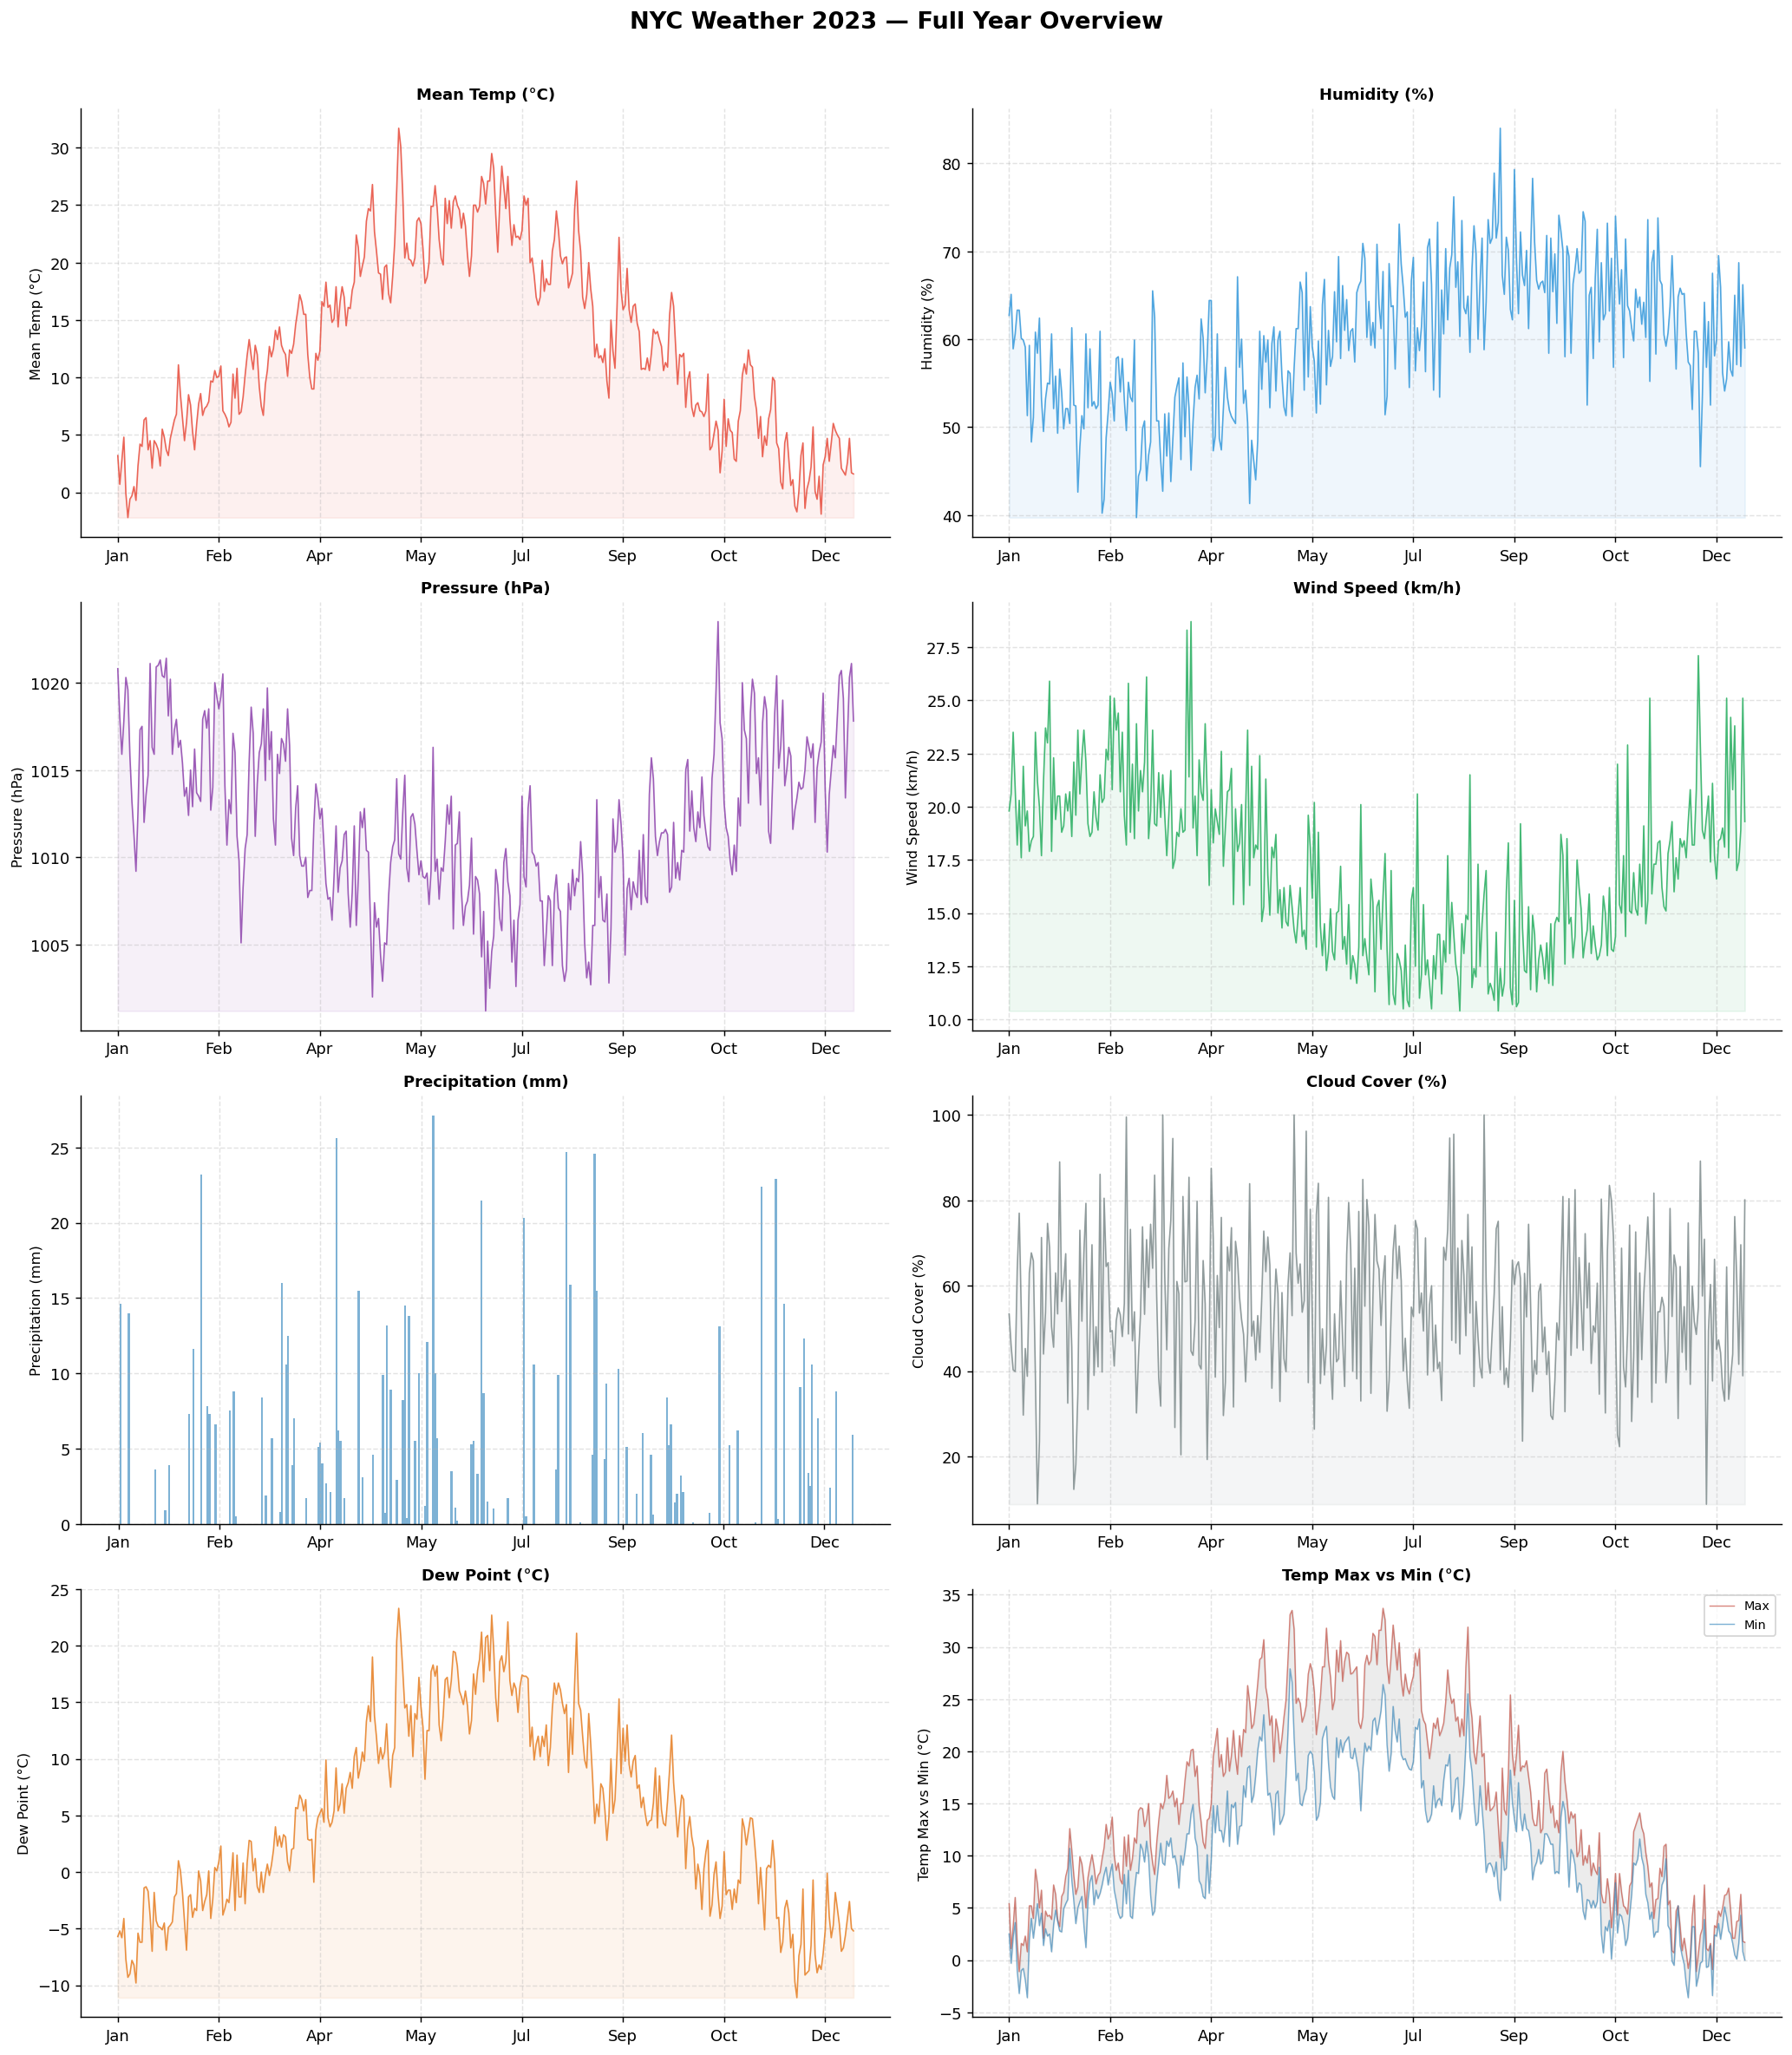

In [8]:
# ── 3.1  Full-year overview ────────────────────────────────────
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
fig.suptitle('NYC Weather 2023 — Full Year Overview', fontsize=15,
             fontweight='bold', y=1.01)

cols_labels = [
    ('temp_mean',      'Mean Temp (°C)',       '#e74c3c'),
    ('humidity',       'Humidity (%)',          '#3498db'),
    ('pressure',       'Pressure (hPa)',        '#8e44ad'),
    ('wind_speed',     'Wind Speed (km/h)',     '#27ae60'),
    ('precipitation',  'Precipitation (mm)',   '#2980b9'),
    ('cloud_cover',    'Cloud Cover (%)',       '#7f8c8d'),
    ('dew_point',      'Dew Point (°C)',        '#e67e22'),
    ('temp_max',       'Temp Max vs Min (°C)',  '#c0392b'),
]

for ax, (col, label, color) in zip(axes.flat, cols_labels):
    if col == 'temp_max':
        ax.plot(df.index, df['temp_max'], color='#c0392b', alpha=0.6,
                linewidth=0.8, label='Max')
        ax.plot(df.index, df['temp_min'], color='#2980b9', alpha=0.6,
                linewidth=0.8, label='Min')
        ax.fill_between(df.index, df['temp_min'], df['temp_max'],
                        alpha=0.15, color='gray')
        ax.legend(fontsize=8)
    elif col == 'precipitation':
        ax.bar(df.index, df[col], color=color, alpha=0.6, width=1)
    else:
        ax.plot(df.index, df[col], color=color, linewidth=0.9, alpha=0.85)
        ax.fill_between(df.index, df[col].min(), df[col],
                        alpha=0.08, color=color)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.set_ylabel(label, fontsize=9)
    ax.set_title(label, fontsize=10, fontweight='bold')

plt.tight_layout()
#plt.savefig('eda_overview.png', dpi=130, bbox_inches='tight')
plt.show()

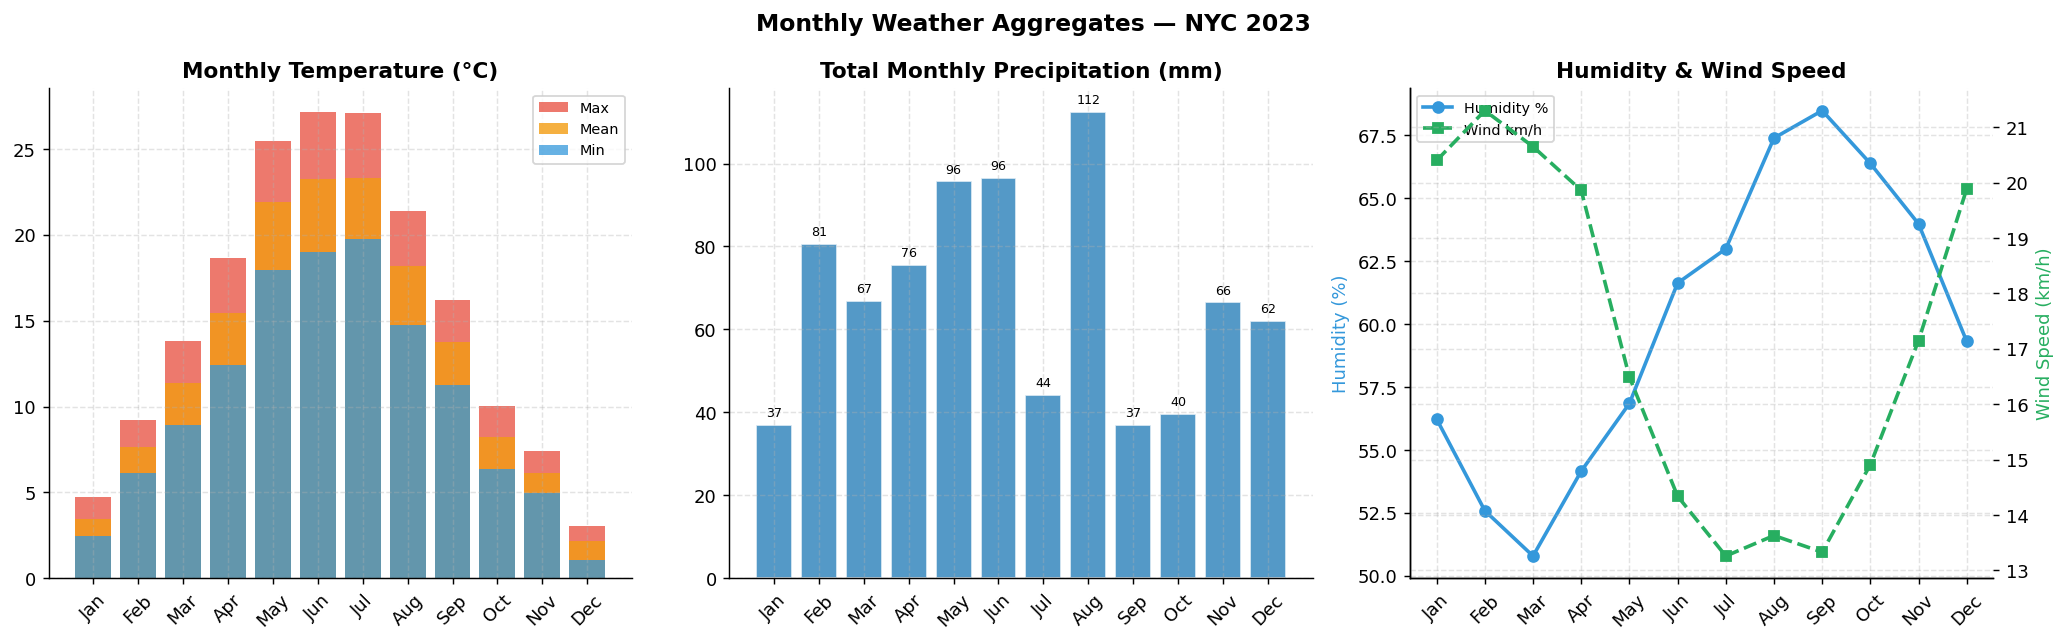

In [11]:
# ── 3.2  Monthly aggregation ───────────────────────────────────
monthly = df.resample('ME').agg({
    'temp_mean'     : 'mean',
    'temp_max'      : 'mean',
    'temp_min'      : 'mean',
    'humidity'      : 'mean',
    'precipitation' : 'sum',
    'wind_speed'    : 'mean',
    'pressure'      : 'mean',
}).round(2)
monthly.index = monthly.index.strftime('%b')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Monthly Weather Aggregates — NYC 2023',
             fontsize=13, fontweight='bold')

# Temperature
ax = axes[0]
ax.bar(monthly.index, monthly['temp_max'], label='Max', color='#e74c3c', alpha=0.75)
ax.bar(monthly.index, monthly['temp_mean'], label='Mean', color='#f39c12', alpha=0.8)
ax.bar(monthly.index, monthly['temp_min'], label='Min', color='#3498db', alpha=0.75)
ax.set_title('Monthly Temperature (°C)', fontweight='bold')
ax.legend(fontsize=8)
ax.tick_params(axis='x', rotation=45)

# Precipitation
ax = axes[1]
ax.bar(monthly.index, monthly['precipitation'],
       color='#2980b9', alpha=0.8, edgecolor='white')
ax.set_title('Total Monthly Precipitation (mm)', fontweight='bold')
ax.tick_params(axis='x', rotation=45)
for i, v in enumerate(monthly['precipitation']):
    ax.text(i, v + 2, f'{v:.0f}', ha='center', fontsize=7)

# Humidity + Wind
ax = axes[2]
ax2 = ax.twinx()
ax.plot(monthly.index, monthly['humidity'], 'o-', color='#3498db',
        linewidth=2, label='Humidity %')
ax2.plot(monthly.index, monthly['wind_speed'], 's--', color='#27ae60',
         linewidth=2, label='Wind km/h')
ax.set_ylabel('Humidity (%)', color='#3498db')
ax2.set_ylabel('Wind Speed (km/h)', color='#27ae60')
ax.set_title('Humidity & Wind Speed', fontweight='bold')
ax.tick_params(axis='x', rotation=45)
lines1, lab1 = ax.get_legend_handles_labels()
lines2, lab2 = ax2.get_legend_handles_labels()
ax.legend(lines1+lines2, lab1+lab2, fontsize=8)

plt.tight_layout()
plt.show()

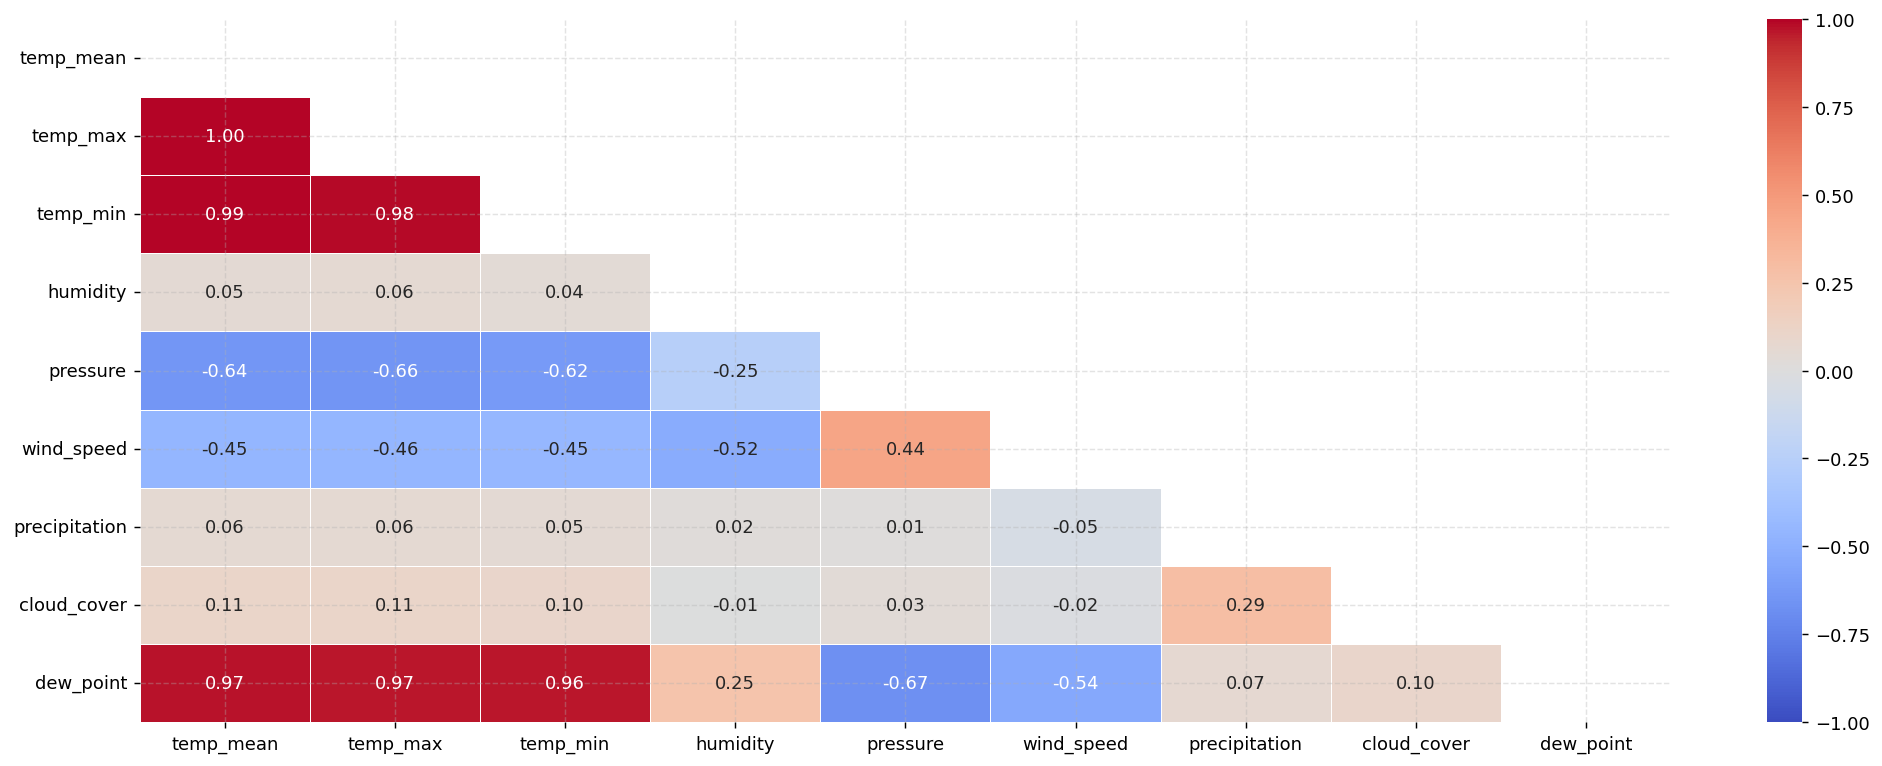

In [16]:
# ── 3.3  Correlation Heatmap ───────────────────────────────────
fig, axes = plt.subplots(1, 1, figsize=(16, 6))

corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

IndexError: list index out of range

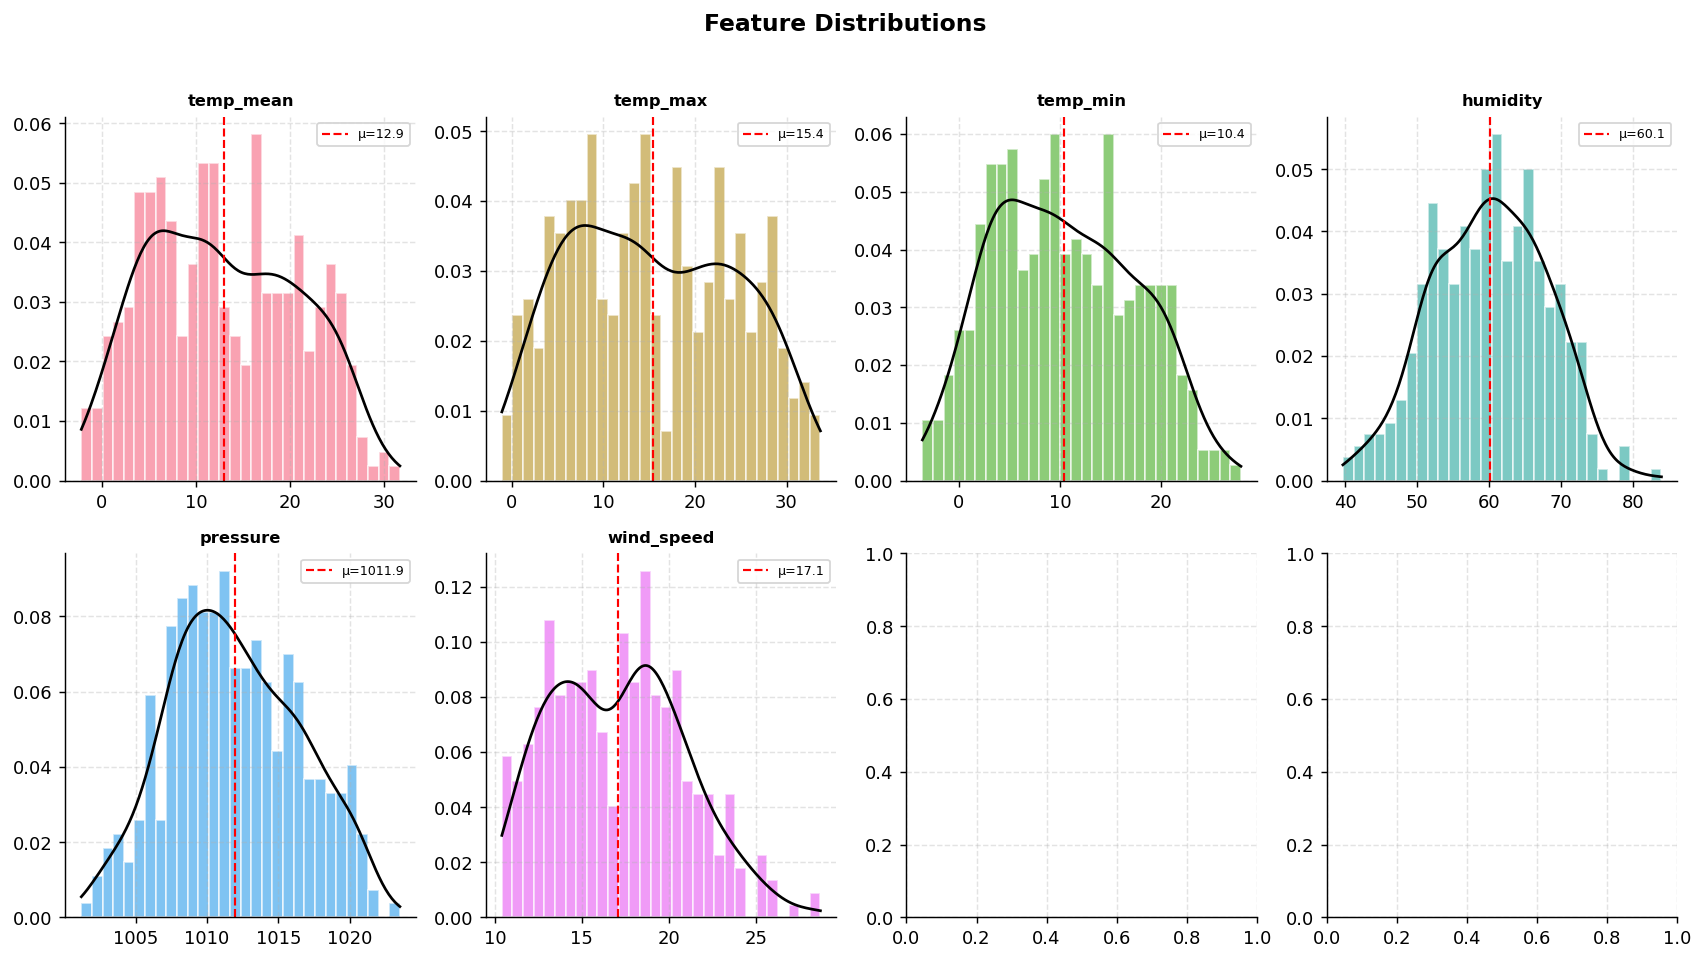

In [17]:
# ── 3.4  Distribution Analysis ─────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Feature Distributions', fontsize=13, fontweight='bold')

for ax, col in zip(axes.flat, df.columns):
    data = df[col].dropna()
    ax.hist(data, bins=30, density=True, alpha=0.65,
            color=sns.color_palette()[list(df.columns).index(col) % 8],
            edgecolor='white')
    # Overlay KDE
    kde_x = np.linspace(data.min(), data.max(), 200)
    kde = stats.gaussian_kde(data)
    ax.plot(kde_x, kde(kde_x), 'k-', linewidth=1.5)
    ax.axvline(data.mean(), color='red', linestyle='--',
               linewidth=1.2, label=f'μ={data.mean():.1f}')
    ax.legend(fontsize=7)
    ax.set_title(col, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

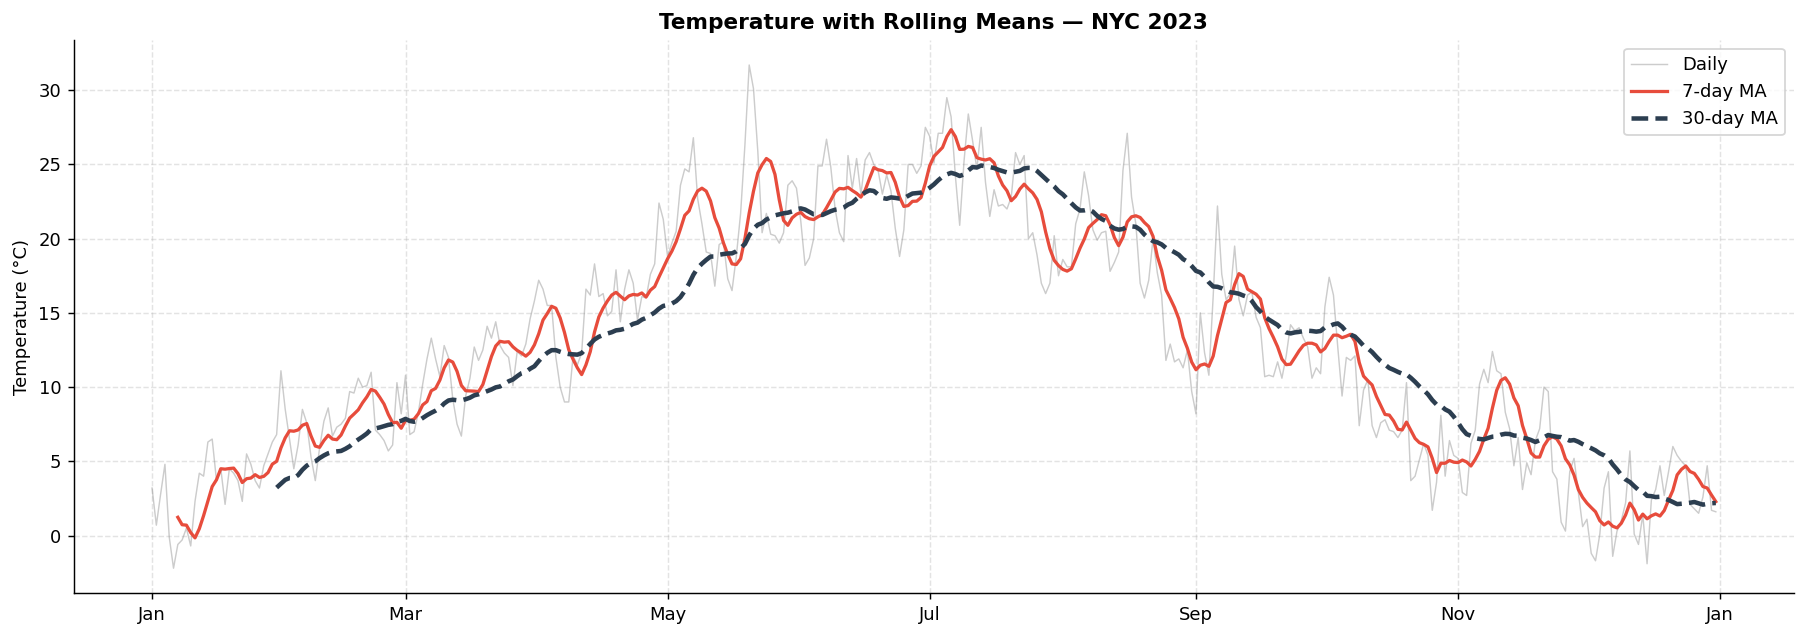

In [18]:
# ── 3.7  7-day & 30-day Rolling Mean ──────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df['temp_mean'], alpha=0.4, color='gray',
        linewidth=0.8, label='Daily')
ax.plot(df.index, df['temp_mean'].rolling(7).mean(),
        color='#e74c3c', linewidth=1.8, label='7-day MA')
ax.plot(df.index, df['temp_mean'].rolling(30).mean(),
        color='#2c3e50', linewidth=2.5, linestyle='--', label='30-day MA')
ax.set_title('Temperature with Rolling Means — NYC 2023',
             fontweight='bold', fontsize=12)
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
#Feature engineering: add lag features for temp_mean
def engineer_features(df, lookback=3):
    """
    Build a rich feature set for weather forecasting.
    """
    fe = df.copy()

    # ── Calendar Features ──────────────────────────────────────
    fe['day_of_year']  = fe.index.dayofyear
    fe['month']        = fe.index.month
    fe['day_of_week']  = fe.index.dayofweek
    fe['week_of_year'] = fe.index.isocalendar().week.astype(int)
    fe['quarter']      = fe.index.quarter
    fe['is_weekend']   = (fe.index.dayofweek >= 5).astype(int)

    # ── Cyclical Encoding ──────────────────────────────────────
    fe['doy_sin'] = np.sin(2 * np.pi * fe['day_of_year'] / 365)
    fe['doy_cos'] = np.cos(2 * np.pi * fe['day_of_year'] / 365)
    fe['month_sin'] = np.sin(2 * np.pi * fe['month'] / 12)
    fe['month_cos'] = np.cos(2 * np.pi * fe['month'] / 12)

    # ── Lag Features (1–lookback days) ────────────────────────
    lag_cols = ['temp_mean', 'temp_max', 'temp_min',
                'humidity', 'pressure', 'wind_speed',
                'precipitation', 'dew_point']
    for lag in range(1, lookback + 1):
        for col in lag_cols:
            fe[f'{col}_lag{lag}'] = fe[col].shift(lag)

    # ── Rolling Statistics (3-day) ─────────────────────────────
    roll_cols = ['temp_mean', 'humidity', 'pressure', 'precipitation']
    for col in roll_cols:
        fe[f'{col}_roll3_mean'] = fe[col].shift(1).rolling(3).mean()
        fe[f'{col}_roll3_std']  = fe[col].shift(1).rolling(3).std()
        fe[f'{col}_roll7_mean'] = fe[col].shift(1).rolling(7).mean()

    # ── Temperature Change Features ────────────────────────────
    fe['temp_diff1']    = fe['temp_mean'].diff(1)          # 1-day change
    fe['temp_diff2']    = fe['temp_mean'].diff(2)          # 2-day change
    fe['temp_range']    = fe['temp_max'] - fe['temp_min']  # daily range

    # ── Interaction Features ───────────────────────────────────
    fe['heat_index']    = fe['temp_mean'] + 0.33 * fe['humidity'] - 4   # simplified
    fe['pressure_diff'] = fe['pressure'].diff(1)  # pressure trend

    # ── Target: next-day mean temperature ─────────────────────
    fe['target'] = fe['temp_mean'].shift(-1)

    # Drop rows with NaN (from lags, diffs, and last row target)
    fe.dropna(inplace=True)

    return fe

df_fe = engineer_features(df, lookback=LOOKBACK)

print(f'Features created : {df_fe.shape[1] - 1}')
print(f'Samples available: {len(df_fe)}')
print(f'\nAll columns ({df_fe.shape[1]}):')
print([c for c in df_fe.columns])

Features created : 60
Samples available: 357

All columns (61):
['temp_mean', 'temp_max', 'temp_min', 'humidity', 'pressure', 'wind_speed', 'precipitation', 'cloud_cover', 'dew_point', 'day_of_year', 'month', 'day_of_week', 'week_of_year', 'quarter', 'is_weekend', 'doy_sin', 'doy_cos', 'month_sin', 'month_cos', 'temp_mean_lag1', 'temp_max_lag1', 'temp_min_lag1', 'humidity_lag1', 'pressure_lag1', 'wind_speed_lag1', 'precipitation_lag1', 'dew_point_lag1', 'temp_mean_lag2', 'temp_max_lag2', 'temp_min_lag2', 'humidity_lag2', 'pressure_lag2', 'wind_speed_lag2', 'precipitation_lag2', 'dew_point_lag2', 'temp_mean_lag3', 'temp_max_lag3', 'temp_min_lag3', 'humidity_lag3', 'pressure_lag3', 'wind_speed_lag3', 'precipitation_lag3', 'dew_point_lag3', 'temp_mean_roll3_mean', 'temp_mean_roll3_std', 'temp_mean_roll7_mean', 'humidity_roll3_mean', 'humidity_roll3_std', 'humidity_roll7_mean', 'pressure_roll3_mean', 'pressure_roll3_std', 'pressure_roll7_mean', 'precipitation_roll3_mean', 'precipitation_ro

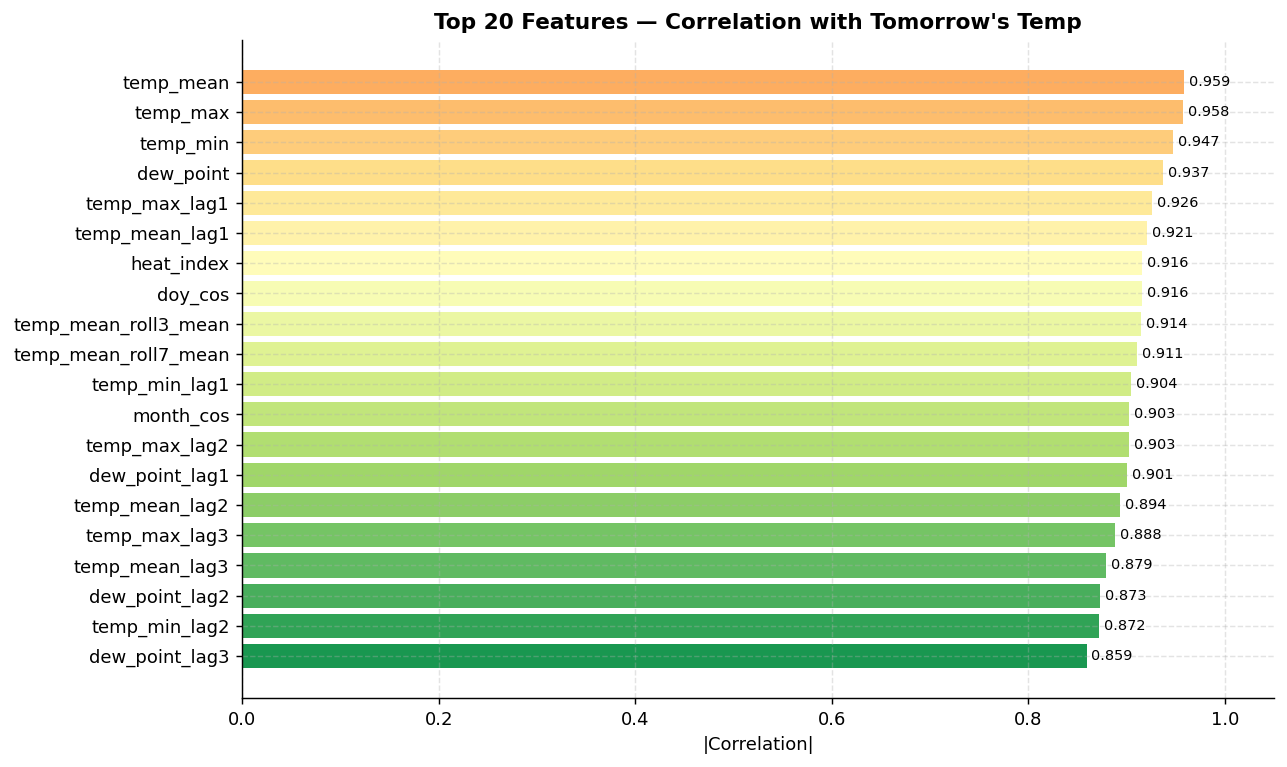

In [21]:
# ── Feature importance preview — correlation with target ───────
feature_corr = df_fe.corr()['target'].drop('target').abs().sort_values(ascending=False)
top20 = feature_corr.head(20)

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(top20))[::-1])
bars = ax.barh(top20.index[::-1], top20.values[::-1], color=colors)
ax.set_title('Top 20 Features — Correlation with Tomorrow\'s Temp',
             fontweight='bold', fontsize=12)
ax.set_xlabel('|Correlation|')
for bar, val in zip(bars, top20.values[::-1]):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=8)
ax.set_xlim(0, 1.05)
plt.tight_layout()
plt.show()

In [22]:
# 80/20 chronological split — NO shuffle (time series!)
SPLIT = int(len(df_fe) * 0.80)

feature_cols = [c for c in df_fe.columns if c != 'target']
X = df_fe[feature_cols].values
y = df_fe['target'].values
dates_all = df_fe.index

X_train, X_test = X[:SPLIT], X[SPLIT:]
y_train, y_test = y[:SPLIT], y[SPLIT:]
dates_train, dates_test = dates_all[:SPLIT], dates_all[SPLIT:]

print(f'Train: {len(X_train)} samples  ({dates_train[0].date()} → {dates_train[-1].date()})')
print(f'Test : {len(X_test)} samples   ({dates_test[0].date()} → {dates_test[-1].date()})')

# ── Scale features ─────────────────────────────────────────────
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_sc = scaler_X.fit_transform(X_train)
X_test_sc  = scaler_X.transform(X_test)

y_train_sc = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_test_sc  = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

# ── 3D reshape for RNN / LSTM: (samples, timesteps, features) ─
# Each sample = 1 timestep of ALL engineered features
X_train_3d = X_train_sc.reshape(X_train_sc.shape[0], 1, X_train_sc.shape[1])
X_test_3d  = X_test_sc.reshape(X_test_sc.shape[0],  1, X_test_sc.shape[1])

print(f'\nRNN/LSTM input shape: {X_train_3d.shape}')

Train: 285 samples  (2023-01-08 → 2023-10-19)
Test : 72 samples   (2023-10-20 → 2023-12-30)

RNN/LSTM input shape: (285, 1, 60)


Each sample contains 1 timestep, So each sample contains 60 input variables.

1. RNN

In [23]:
def build_rnn(input_shape):
    inp = keras.Input(shape=input_shape)
    x = layers.SimpleRNN(64, activation='tanh', return_sequences=True)(inp)
    x = layers.Dropout(0.2)(x)
    x = layers.SimpleRNN(32, activation='tanh')(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(16, activation='relu')(x)
    out = layers.Dense(1)(x)
    model = models.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='mse', metrics=['mae'])
    return model

rnn_model = build_rnn((1, X_train_3d.shape[2]))
rnn_model.summary()

callbacks = [
    EarlyStopping(patience=12, restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-5, verbose=0)
]

print('\nTraining RNN...')
t0 = time.time()
rnn_hist = rnn_model.fit(
    X_train_3d, y_train_sc,
    epochs=100, batch_size=16,
    validation_split=0.15,
    callbacks=callbacks, verbose=0
)
rnn_time = time.time() - t0
print(f'RNN training done in {rnn_time:.1f}s  '
      f'(best val_loss={min(rnn_hist.history["val_loss"]):.5f})')

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1, 60)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 1, 64)          │         8,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,649 (45.50 KB)

 Trainable params: 11,649 (45.50 KB)

 Non-trainable params: 0 (0.00 B)


Training RNN...
RNN training done in 9.7s  (best val_loss=0.00390)


2. LSTM

In [24]:
def build_lstm(input_shape):
    inp = keras.Input(shape=input_shape)
    x = layers.LSTM(64, return_sequences=True)(inp)
    x = layers.Dropout(0.2)(x)
    x = layers.LSTM(32)(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(16, activation='relu')(x)
    out = layers.Dense(1)(x)
    model = models.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='mse', metrics=['mae'])
    return model

lstm_model = build_lstm((1, X_train_3d.shape[2]))
lstm_model.summary()

print('\nTraining LSTM...')
t0 = time.time()
lstm_hist = lstm_model.fit(
    X_train_3d, y_train_sc,
    epochs=100, batch_size=16,
    validation_split=0.15,
    callbacks=callbacks, verbose=0
)
lstm_time = time.time() - t0
print(f'LSTM training done in {lstm_time:.1f}s  '
      f'(best val_loss={min(lstm_hist.history["val_loss"]):.5f})')

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1, 60)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 1, 64)          │        32,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,961 (175.63 KB)

 Trainable params: 44,961 (175.63 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM...
LSTM training done in 4.1s  (best val_loss=0.00722)


3. XGBoost

In [ ]:
print('Training XGBoost Regressor...')
t0 = time.time()

xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1
)
xgb_model.fit(
    X_train_sc, y_train,
    eval_set=[(X_test_sc, y_test)],
    verbose=100
)
xgb_time = time.time() - t0
print(f'XGBoost done in {xgb_time:.1f}s')

Training XGBoost Regressor...
[0]	validation_0-rmse:11.21102
[100]	validation_0-rmse:3.25426
[200]	validation_0-rmse:3.15466
[300]	validation_0-rmse:3.15324
[400]	validation_0-rmse:3.15241
[499]	validation_0-rmse:3.14806
XGBoost done in 0.5s


4. RF

In [26]:
print('Training Random Forest Regressor...')
t0 = time.time()

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=SEED,
    n_jobs=-1
)
rf_model.fit(X_train_sc, y_train)
rf_time = time.time() - t0
print(f'Random Forest done in {rf_time:.1f}s')

Training Random Forest Regressor...
Random Forest done in 0.4s


In [28]:
def inverse_transform_rnn(preds_sc, scaler):
    return scaler.inverse_transform(preds_sc.reshape(-1, 1)).ravel()

def compute_metrics(y_true, y_pred, name, train_time):
    rmse  = np.sqrt(mean_squared_error(y_true, y_pred))
    mae   = mean_absolute_error(y_true, y_pred)
    mape  = mean_absolute_percentage_error(y_true, y_pred) * 100
    r2    = r2_score(y_true, y_pred)
    return {'Model': name, 'RMSE': rmse, 'MAE': mae,
            'MAPE%': mape, 'R²': r2, 'Train_Time_s': train_time}

# Predict
rnn_pred  = inverse_transform_rnn(rnn_model.predict(X_test_3d, verbose=0), scaler_y)
lstm_pred = inverse_transform_rnn(lstm_model.predict(X_test_3d, verbose=0), scaler_y)
xgb_pred  = xgb_model.predict(X_test_sc)
rf_pred   = rf_model.predict(X_test_sc)

# Metrics
results = pd.DataFrame([
    compute_metrics(y_test, rnn_pred,  'RNN',           rnn_time),
    compute_metrics(y_test, lstm_pred, 'LSTM',          lstm_time),
    compute_metrics(y_test, xgb_pred,  'XGBoost',      xgb_time),
    compute_metrics(y_test, rf_pred,   'Random Forest', rf_time),
])
results = results.round({'RMSE': 4, 'MAE': 4, 'MAPE%': 2, 'R²': 4, 'Train_Time_s': 1})

print('='*62)
print('          WEATHER FORECASTING — MODEL COMPARISON')
print('='*62)
print(results.to_string(index=False))
print('='*62)
best = results.loc[results['RMSE'].idxmin()]
print(f'\nBest Model: {best["Model"]}  (RMSE={best["RMSE"]:.4f}°C)')

          WEATHER FORECASTING — MODEL COMPARISON
        Model   RMSE    MAE  MAPE%      R²  Train_Time_s
          RNN 2.4899 2.0892 113.70  0.4220           9.7
         LSTM 9.2848 8.8007 806.15 -7.0377           4.1
      XGBoost 3.1481 2.5088 291.23  0.0760           0.5
Random Forest 3.1097 2.4714 305.60  0.0984           0.4

Best Model: RNN  (RMSE=2.4899°C)


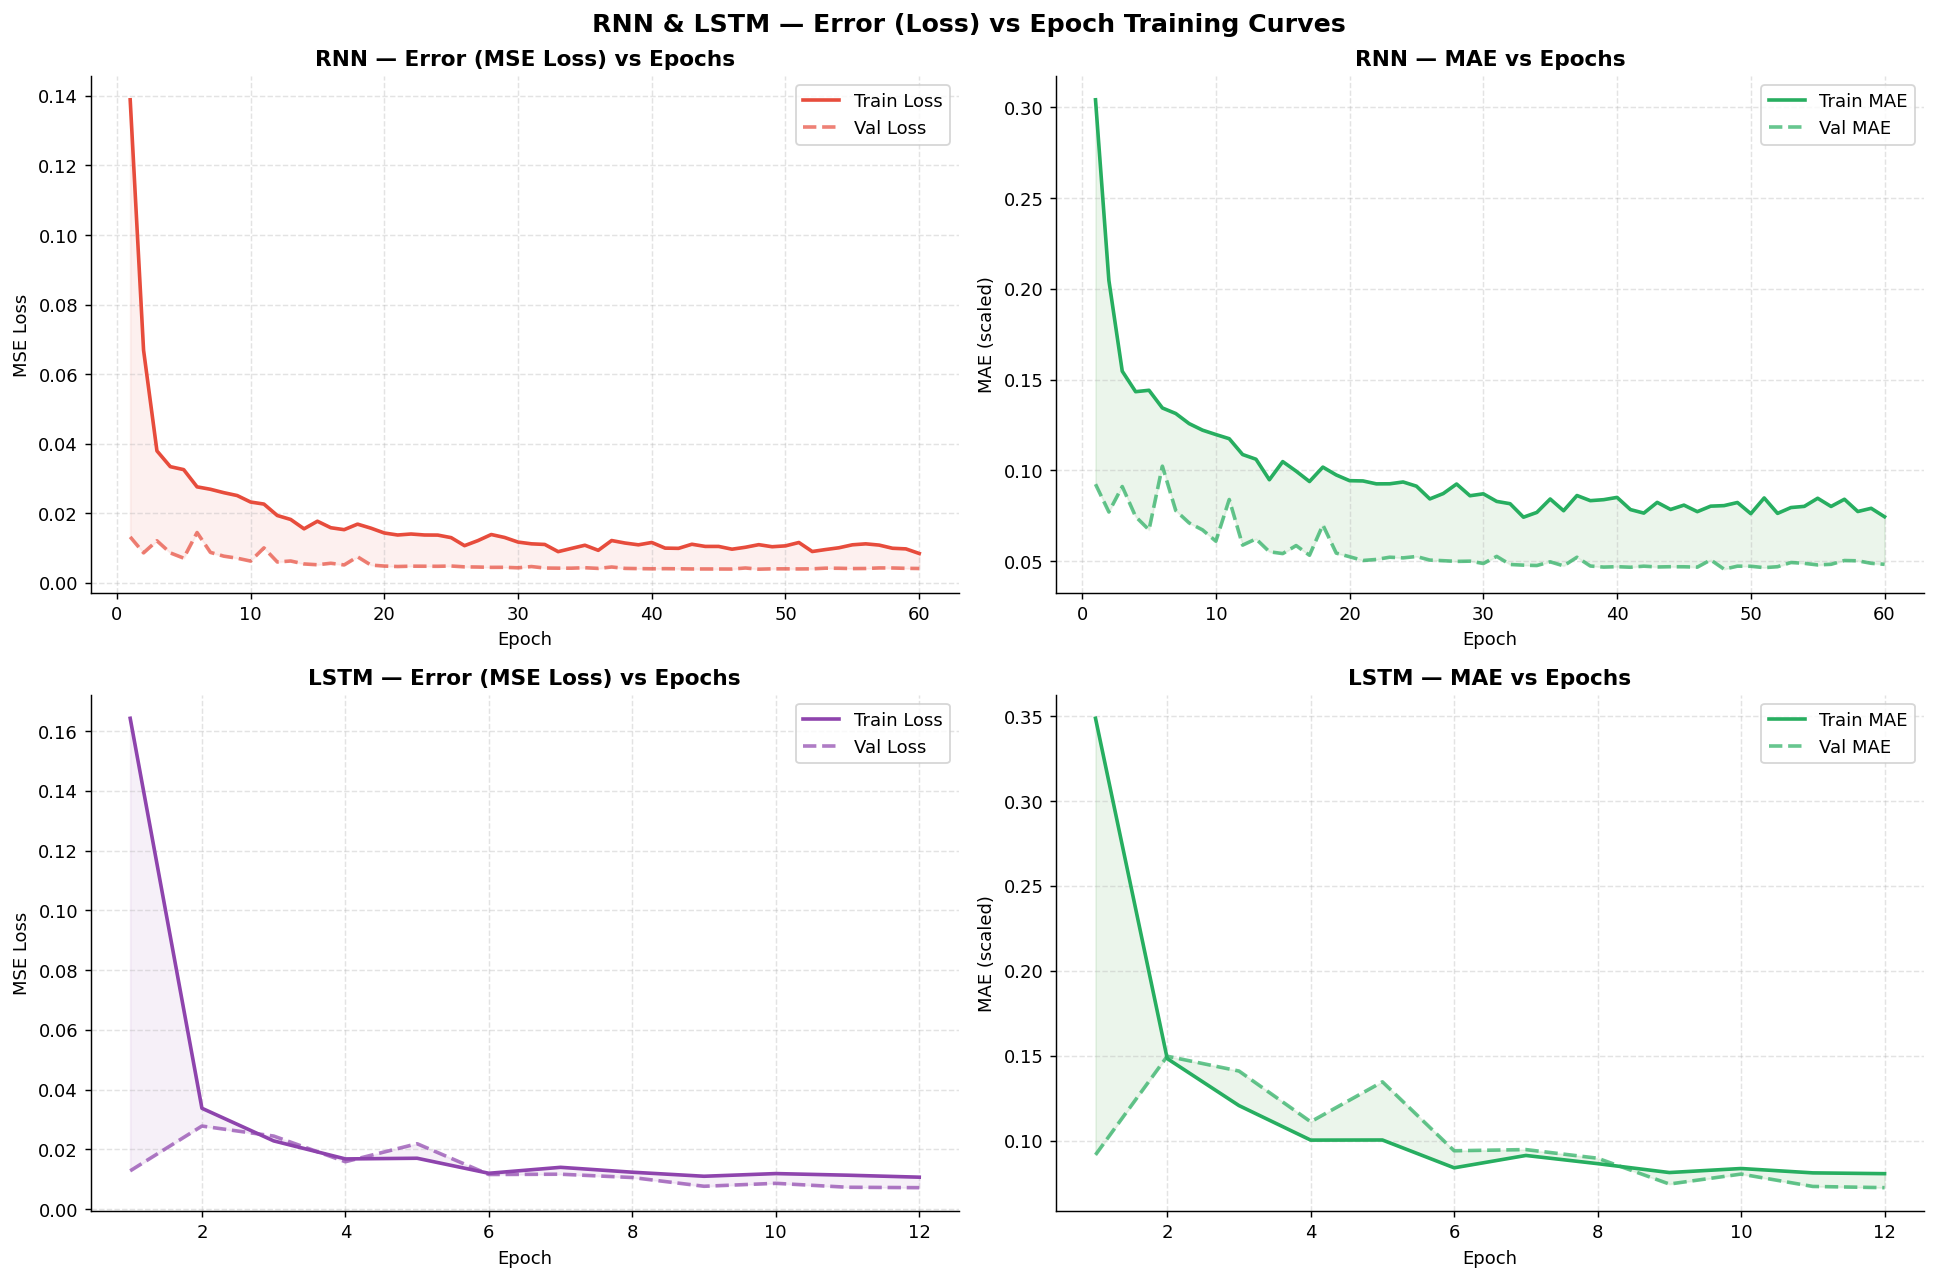

In [29]:
# ── RNN & LSTM Training Curves ─────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('RNN & LSTM — Error (Loss) vs Epoch Training Curves',
             fontsize=14, fontweight='bold')

for row, (hist, name, color) in enumerate([
        (rnn_hist,  'RNN',  '#e74c3c'),
        (lstm_hist, 'LSTM', '#8e44ad')]):
    h = hist.history
    ep = range(1, len(h['loss']) + 1)

    # Loss (Error)
    ax = axes[row][0]
    ax.plot(ep, h['loss'],     color=color, linewidth=2,    label='Train Loss')
    ax.plot(ep, h['val_loss'], color=color, linewidth=2,
            linestyle='--', alpha=0.7, label='Val Loss')
    ax.fill_between(ep, h['loss'], h['val_loss'], alpha=0.08, color=color)
    ax.set_title(f'{name} — Error (MSE Loss) vs Epochs', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.legend()

    # MAE (as proxy for accuracy)
    ax = axes[row][1]
    ax.plot(ep, h['mae'],     color='#27ae60', linewidth=2,  label='Train MAE')
    ax.plot(ep, h['val_mae'], color='#27ae60', linewidth=2,
            linestyle='--', alpha=0.7, label='Val MAE')
    ax.fill_between(ep, h['mae'], h['val_mae'], alpha=0.08, color='green')
    ax.set_title(f'{name} — MAE vs Epochs', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MAE (scaled)')
    ax.legend()

plt.tight_layout()
plt.savefig('rnn_lstm_training_curves.png', dpi=130, bbox_inches='tight')
plt.show()

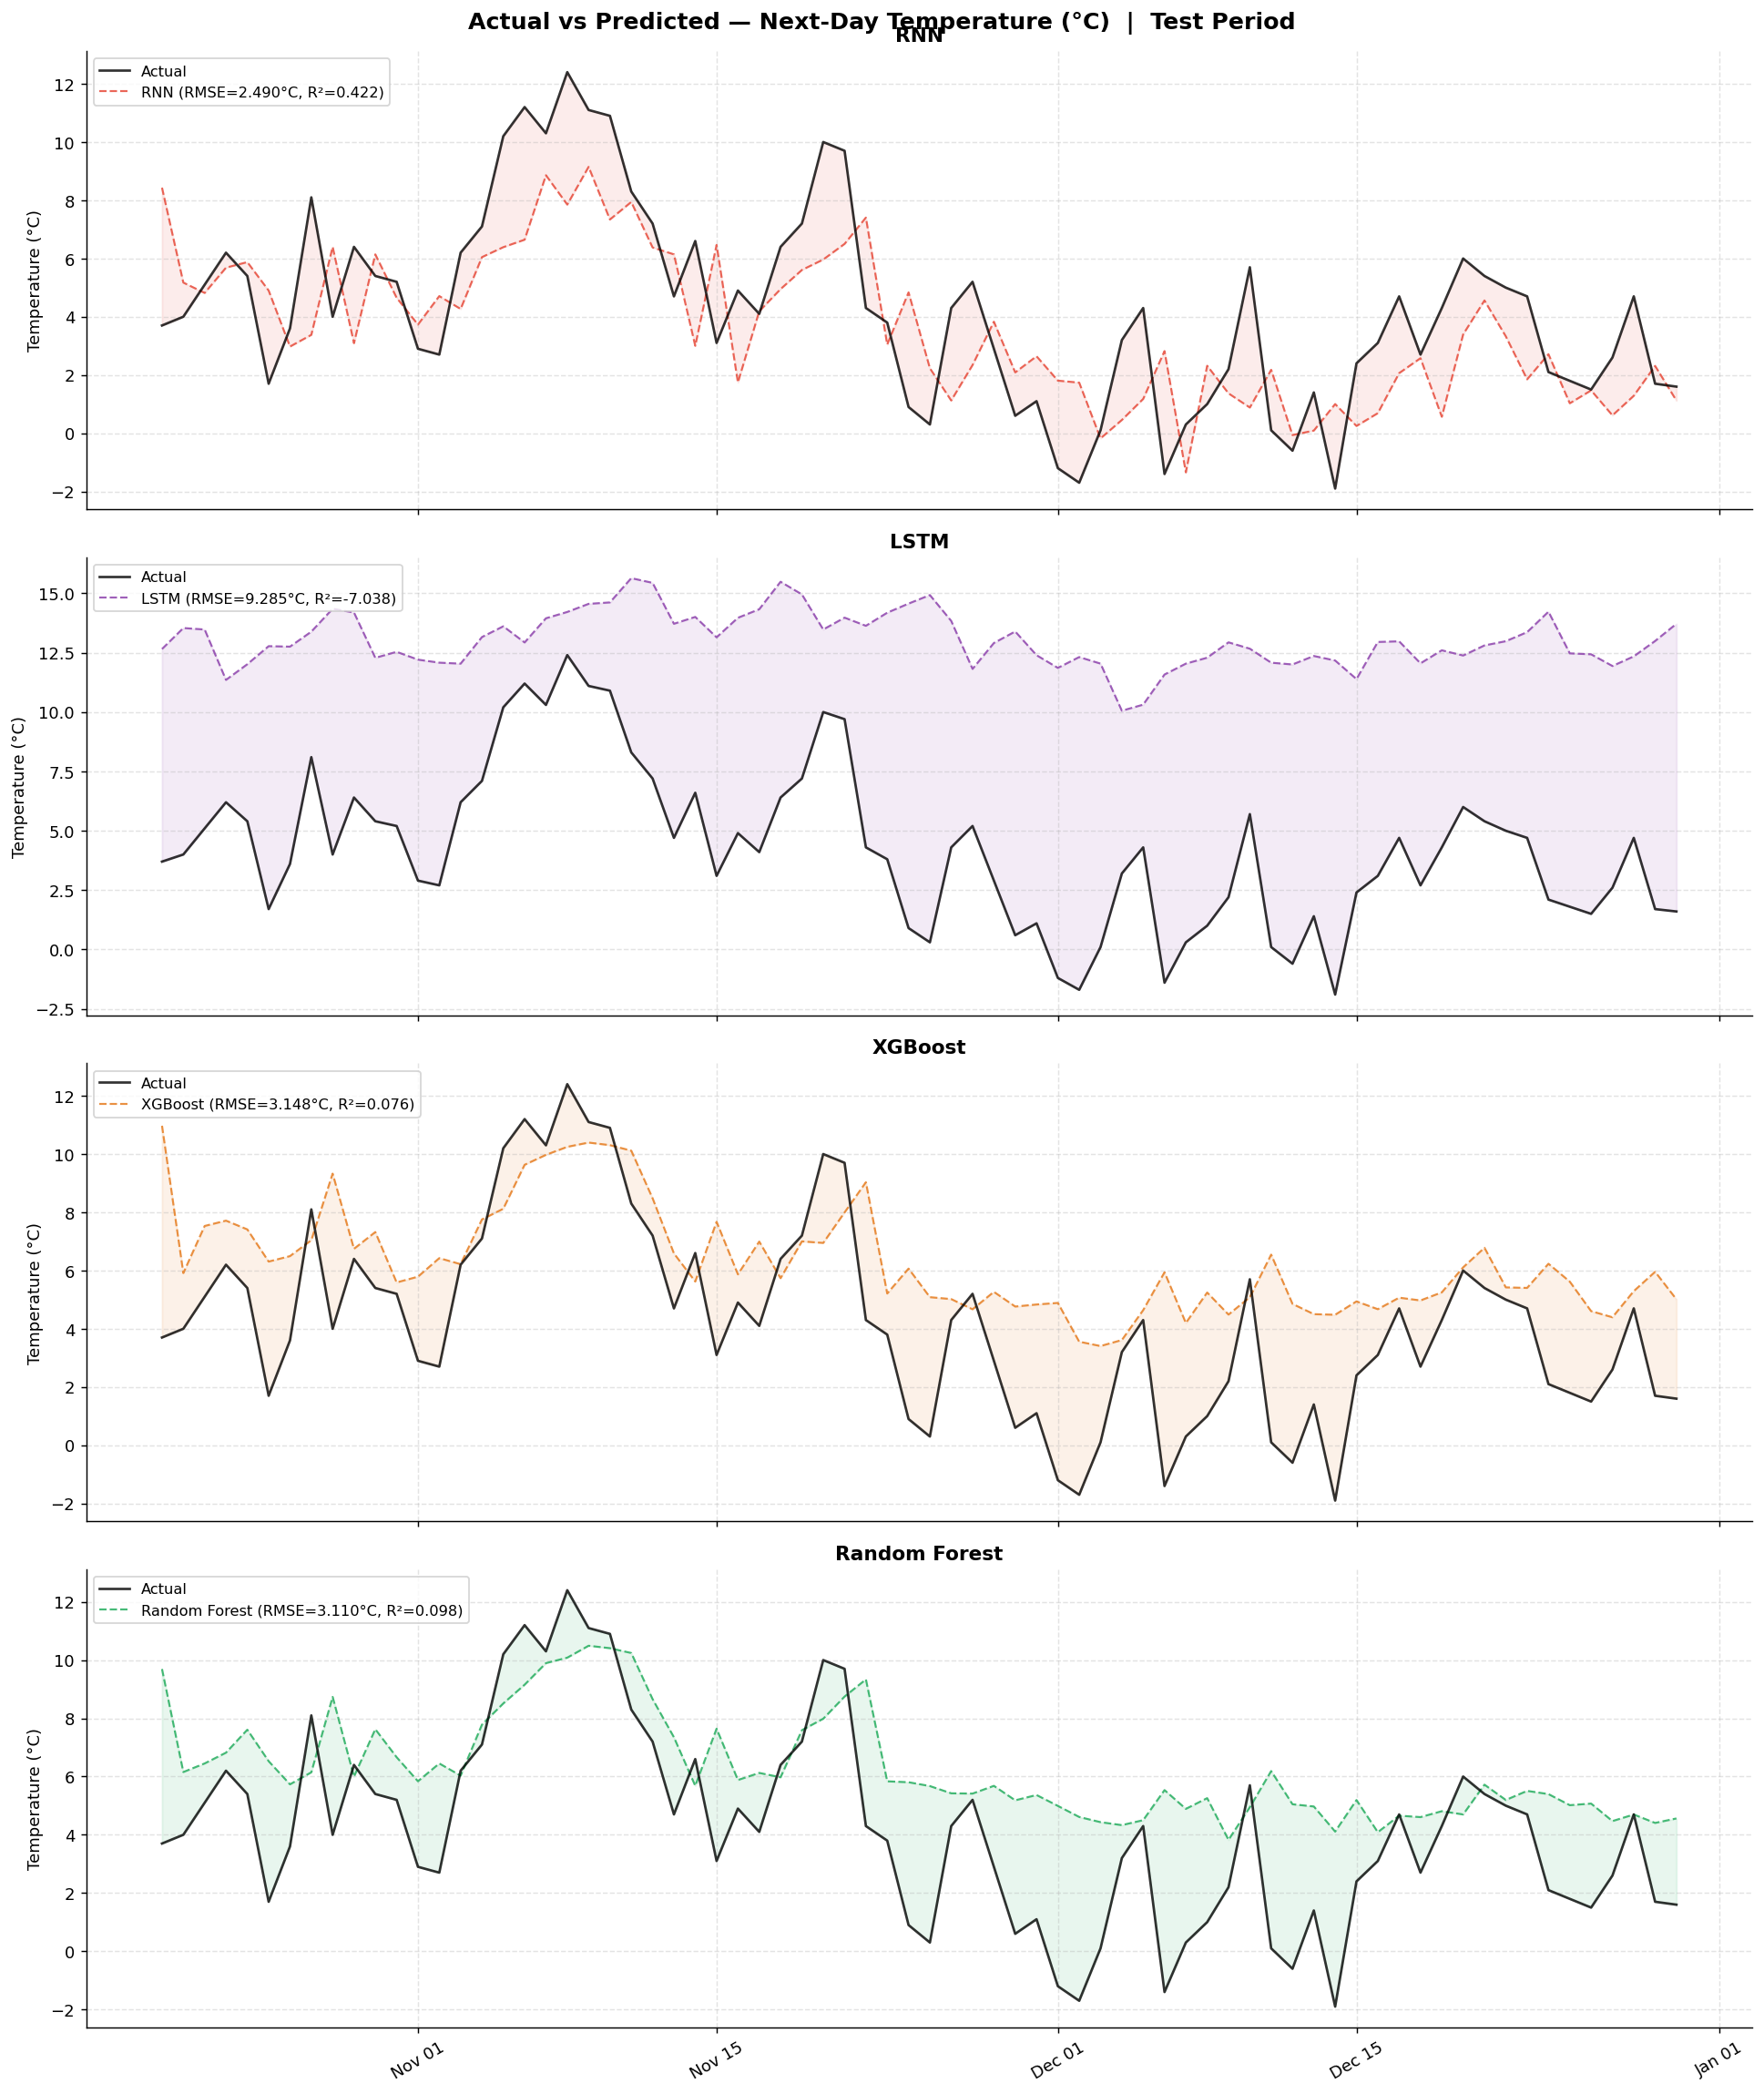

In [31]:
fig, axes = plt.subplots(4, 1, figsize=(15, 18), sharex=True)
fig.suptitle('Actual vs Predicted — Next-Day Temperature (°C)  |  Test Period',
             fontsize=14, fontweight='bold')

preds_dict = {'RNN': rnn_pred, 'LSTM': lstm_pred,
              'XGBoost': xgb_pred, 'Random Forest': rf_pred}
colors_dict = {'RNN': '#e74c3c', 'LSTM': '#8e44ad',
               'XGBoost': '#e67e22', 'Random Forest': '#27ae60'}

for ax, (name, pred) in zip(axes, preds_dict.items()):
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2   = r2_score(y_test, pred)
    ax.plot(dates_test, y_test, 'k-', linewidth=1.5,
            alpha=0.8, label='Actual', zorder=3)
    ax.plot(dates_test, pred, color=colors_dict[name], linewidth=1.2,
            alpha=0.85, linestyle='--', label=f'{name} (RMSE={rmse:.3f}°C, R²={r2:.3f})')
    ax.fill_between(dates_test, y_test, pred,
                    alpha=0.1, color=colors_dict[name])
    ax.set_ylabel('Temperature (°C)')
    ax.legend(fontsize=9, loc='upper left')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.set_title(f'{name}', fontweight='bold')

plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=130, bbox_inches='tight')
plt.show()

In [33]:
# ── Styled comparison table ────────────────────────────────────
print('\n' + '='*66)
print('      WEATHER FORECASTING — FULL MODEL COMPARISON TABLE')
print('='*66)
print(f'  Task  : Predict TOMORROW\'s mean temperature')
print(f'  Input : Last {LOOKBACK} days of weather features (engineered)')
print(f'  Data  : NYC 2023 (365 days), 80/20 chronological split')
print('='*66)
print(results.to_string(index=False))
print('='*66)

# Display styled
results.style \
    .set_caption(f'Weather Forecasting — Model Comparison (Predict Next-Day Temp)') \
    .format({'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'MAPE%': '{:.2f}',
             'R²': '{:.4f}', 'Train_Time_s': '{:.1f}'}) \
    .highlight_min(subset=['RMSE','MAE','MAPE%'], color='#c6efce') \
    .highlight_max(subset=['R²'], color='#c6efce') \
    .highlight_min(subset=['Train_Time_s'], color='#ffeb9c')


      WEATHER FORECASTING — FULL MODEL COMPARISON TABLE
  Task  : Predict TOMORROW's mean temperature
  Input : Last 3 days of weather features (engineered)
  Data  : NYC 2023 (365 days), 80/20 chronological split
        Model   RMSE    MAE  MAPE%      R²  Train_Time_s
          RNN 2.4899 2.0892 113.70  0.4220           9.7
         LSTM 9.2848 8.8007 806.15 -7.0377           4.1
      XGBoost 3.1481 2.5088 291.23  0.0760           0.5
Random Forest 3.1097 2.4714 305.60  0.0984           0.4


,Model,RMSE,MAE,MAPE%,R²,Train_Time_s
0,RNN,2.4899,2.0892,113.70,0.4220,9.7
1,LSTM,9.2848,8.8007,806.15,-7.0377,4.1
2,XGBoost,3.1481,2.5088,291.23,0.0760,0.5
3,Random Forest,3.1097,2.4714,305.60,0.0984,0.4


Future Prediction

In [37]:
FORECAST_DAYS = 30

# ── Last date in our dataset ──────────────────────────────────
last_date = df_fe.index[-1]                    # 2023-12-30 (last usable row)
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=FORECAST_DAYS, freq='D'
)
print(f'Forecasting: {future_dates[0].date()} → {future_dates[-1].date()}')

# ── Build "future" feature rows autoregressively ──────────────
# We keep a rolling buffer of the last few actual df rows
# and update temp_mean with predictions.

# Working copy of raw df — we'll append predicted rows to it
df_rolling = df.copy().astype(float)

future_temps = []
future_temp_means = []

for step, future_date in enumerate(future_dates):

    # ── Compute exogenous values for this future date ─────────
    doy = future_date.dayofyear

    # Seasonal expected values (same model used in data generation)
    exp_temp      = 13 + 11 * np.sin(2*np.pi*(doy - 80)/365)
    exp_humidity  = 60 + 8  * np.sin(2*np.pi*(doy - 160)/365)
    exp_pressure  = 1013 + 5* np.cos(2*np.pi*(doy - 10)/365)
    exp_wind      = 14 + 4  * np.cos(2*np.pi*(doy - 40)/365)
    exp_diurnal   = 5 + 3   * np.sin(2*np.pi*(doy - 80)/365)

    # Use last known actual + small random perturbation for realism
    last_temp   = df_rolling['temp_mean'].iloc[-1]
    noise_scale = 1.0  # realistic day-to-day noise (°C)

    # For exogenous vars: blend seasonal expected + last known (persistence)
    blend = 0.5
    new_row = {
        'temp_mean'     : last_temp,                       # placeholder; will be predicted
        'temp_max'      : last_temp + exp_diurnal/2,
        'temp_min'      : last_temp - exp_diurnal/2,
        'humidity'      : blend*exp_humidity + (1-blend)*df_rolling['humidity'].iloc[-1],
        'pressure'      : blend*exp_pressure + (1-blend)*df_rolling['pressure'].iloc[-1],
        'wind_speed'    : blend*exp_wind     + (1-blend)*df_rolling['wind_speed'].iloc[-1],
        'precipitation' : max(0, df_rolling['precipitation'].iloc[-3:].mean() * 0.8),
        'cloud_cover'   : df_rolling['cloud_cover'].iloc[-3:].mean(),
        'dew_point'     : last_temp - (100 - exp_humidity)/5,
    }

    # Temporarily append to get feature engineering to work
    new_df_row = pd.DataFrame([new_row], index=[future_date])
    new_df_row.index.name = 'date'
    df_rolling = pd.concat([df_rolling, new_df_row])

    # Engineer features for the full extended dataframe, grab last row
    fe_extended = engineer_features(df_rolling, lookback=LOOKBACK)

    # Get the feature row for this future date
    if future_date not in fe_extended.index:
        # Not enough lag data yet — use last available feature row
        feat_row = fe_extended[feature_cols].iloc[-1].values
    else:
        feat_row = fe_extended.loc[future_date, feature_cols].values

    # Scale & reshape for RNN
    feat_scaled = scaler_X.transform(feat_row.reshape(1, -1))
    feat_3d     = feat_scaled.reshape(1, 1, feat_scaled.shape[1])

    # Predict
    pred_scaled = rnn_model.predict(feat_3d, verbose=0)[0][0]
    pred_temp   = scaler_y.inverse_transform([[pred_scaled]])[0][0]

    # Update the row we appended with the predicted temp
    df_rolling.loc[future_date, 'temp_mean'] = pred_temp
    df_rolling.loc[future_date, 'temp_max']  = pred_temp + exp_diurnal/2
    df_rolling.loc[future_date, 'temp_min']  = pred_temp - exp_diurnal/2
    df_rolling.loc[future_date, 'dew_point'] = pred_temp - (100 - exp_humidity)/5

    future_temps.append(pred_temp)
    if (step+1) % 5 == 0 or step == 0:
        print(f'  Day +{step+1:02d}  {future_date.date()}  →  {pred_temp:.2f}°C')

future_temps = np.array(future_temps)
print(f'\nForecast range: {future_temps.min():.1f}°C → {future_temps.max():.1f}°C')
print(f'Forecast mean : {future_temps.mean():.1f}°C')

Forecasting: 2023-12-31 → 2024-01-29
  Day +01  2023-12-31  →  -0.25°C
  Day +05  2024-01-04  →  2.85°C
  Day +10  2024-01-09  →  4.50°C
  Day +15  2024-01-14  →  5.12°C
  Day +20  2024-01-19  →  4.49°C
  Day +25  2024-01-24  →  3.77°C
  Day +30  2024-01-29  →  3.27°C

Forecast range: -0.3°C → 5.2°C
Forecast mean : 3.8°C


In [ ]:
# # ── Autoregressive 30-day forecast ────────────────────────────
# last_date    = df_fe.index[-1]
# future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1),
#                               periods=FORECAST_DAYS, freq='D')
# df_rolling   = df.copy().astype(float)
# future_temps = []

# for step, future_date in enumerate(future_dates):
#     doy = future_date.dayofyear
#     exp_temp     = 13 + 11*np.sin(2*np.pi*(doy-80)/365)
#     exp_humidity = 60 + 8*np.sin(2*np.pi*(doy-160)/365)
#     exp_pressure = 1013 + 5*np.cos(2*np.pi*(doy-10)/365)
#     exp_wind     = 14 + 4*np.cos(2*np.pi*(doy-40)/365)
#     exp_diurnal  = 5 + 3*np.sin(2*np.pi*(doy-80)/365)
#     last_temp    = df_rolling['temp_mean'].iloc[-1]
#     blend        = 0.5
#     new_row = {
#         'temp_mean':last_temp,'temp_max':last_temp+exp_diurnal/2,
#         'temp_min':last_temp-exp_diurnal/2,
#         'humidity':blend*exp_humidity+(1-blend)*df_rolling['humidity'].iloc[-1],
#         'pressure':blend*exp_pressure+(1-blend)*df_rolling['pressure'].iloc[-1],
#         'wind_speed':blend*exp_wind+(1-blend)*df_rolling['wind_speed'].iloc[-1],
#         'precipitation':max(0,df_rolling['precipitation'].iloc[-3:].mean()*0.8),
#         'cloud_cover':df_rolling['cloud_cover'].iloc[-3:].mean(),
#         'dew_point':last_temp-(100-exp_humidity)/5,
#     }
#     new_df_row = pd.DataFrame([new_row], index=[future_date])
#     new_df_row.index.name = 'date'
#     df_rolling = pd.concat([df_rolling, new_df_row])
#     fe_ext = engineer_features(df_rolling, lookback=LOOKBACK)
#     feat_row   = fe_ext.loc[future_date, feature_cols].values if future_date in fe_ext.index else fe_ext[feature_cols].iloc[-1].values
#     feat_scaled = scaler_X.transform(feat_row.reshape(1,-1))
#     pred_sc     = rnn_model.predict(feat_scaled.reshape(1,1,-1), verbose=0)[0][0]
#     pred_temp   = scaler_y.inverse_transform([[pred_sc]])[0][0]
#     df_rolling.loc[future_date,'temp_mean'] = pred_temp
#     df_rolling.loc[future_date,'temp_max']  = pred_temp + exp_diurnal/2
#     df_rolling.loc[future_date,'temp_min']  = pred_temp - exp_diurnal/2
#     df_rolling.loc[future_date,'dew_point'] = pred_temp-(100-exp_humidity)/5
#     future_temps.append(pred_temp)

# future_temps = np.array(future_temps)
# uncertainty  = np.array([1.5*np.sqrt(i+1)*0.4 for i in range(FORECAST_DAYS)])
# upper = future_temps + uncertainty
# lower = future_temps - uncertainty
# print(f'Forecast: {future_dates[0].date()} → {future_dates[-1].date()}')
# print(f'Range   : {future_temps.min():.1f}°C → {future_temps.max():.1f}°C  |  Mean: {future_temps.mean():.1f}°C')

Forecast: 2023-12-31 → 2024-01-29
Range   : -0.3°C → 5.2°C  |  Mean: 3.8°C


In [39]:
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

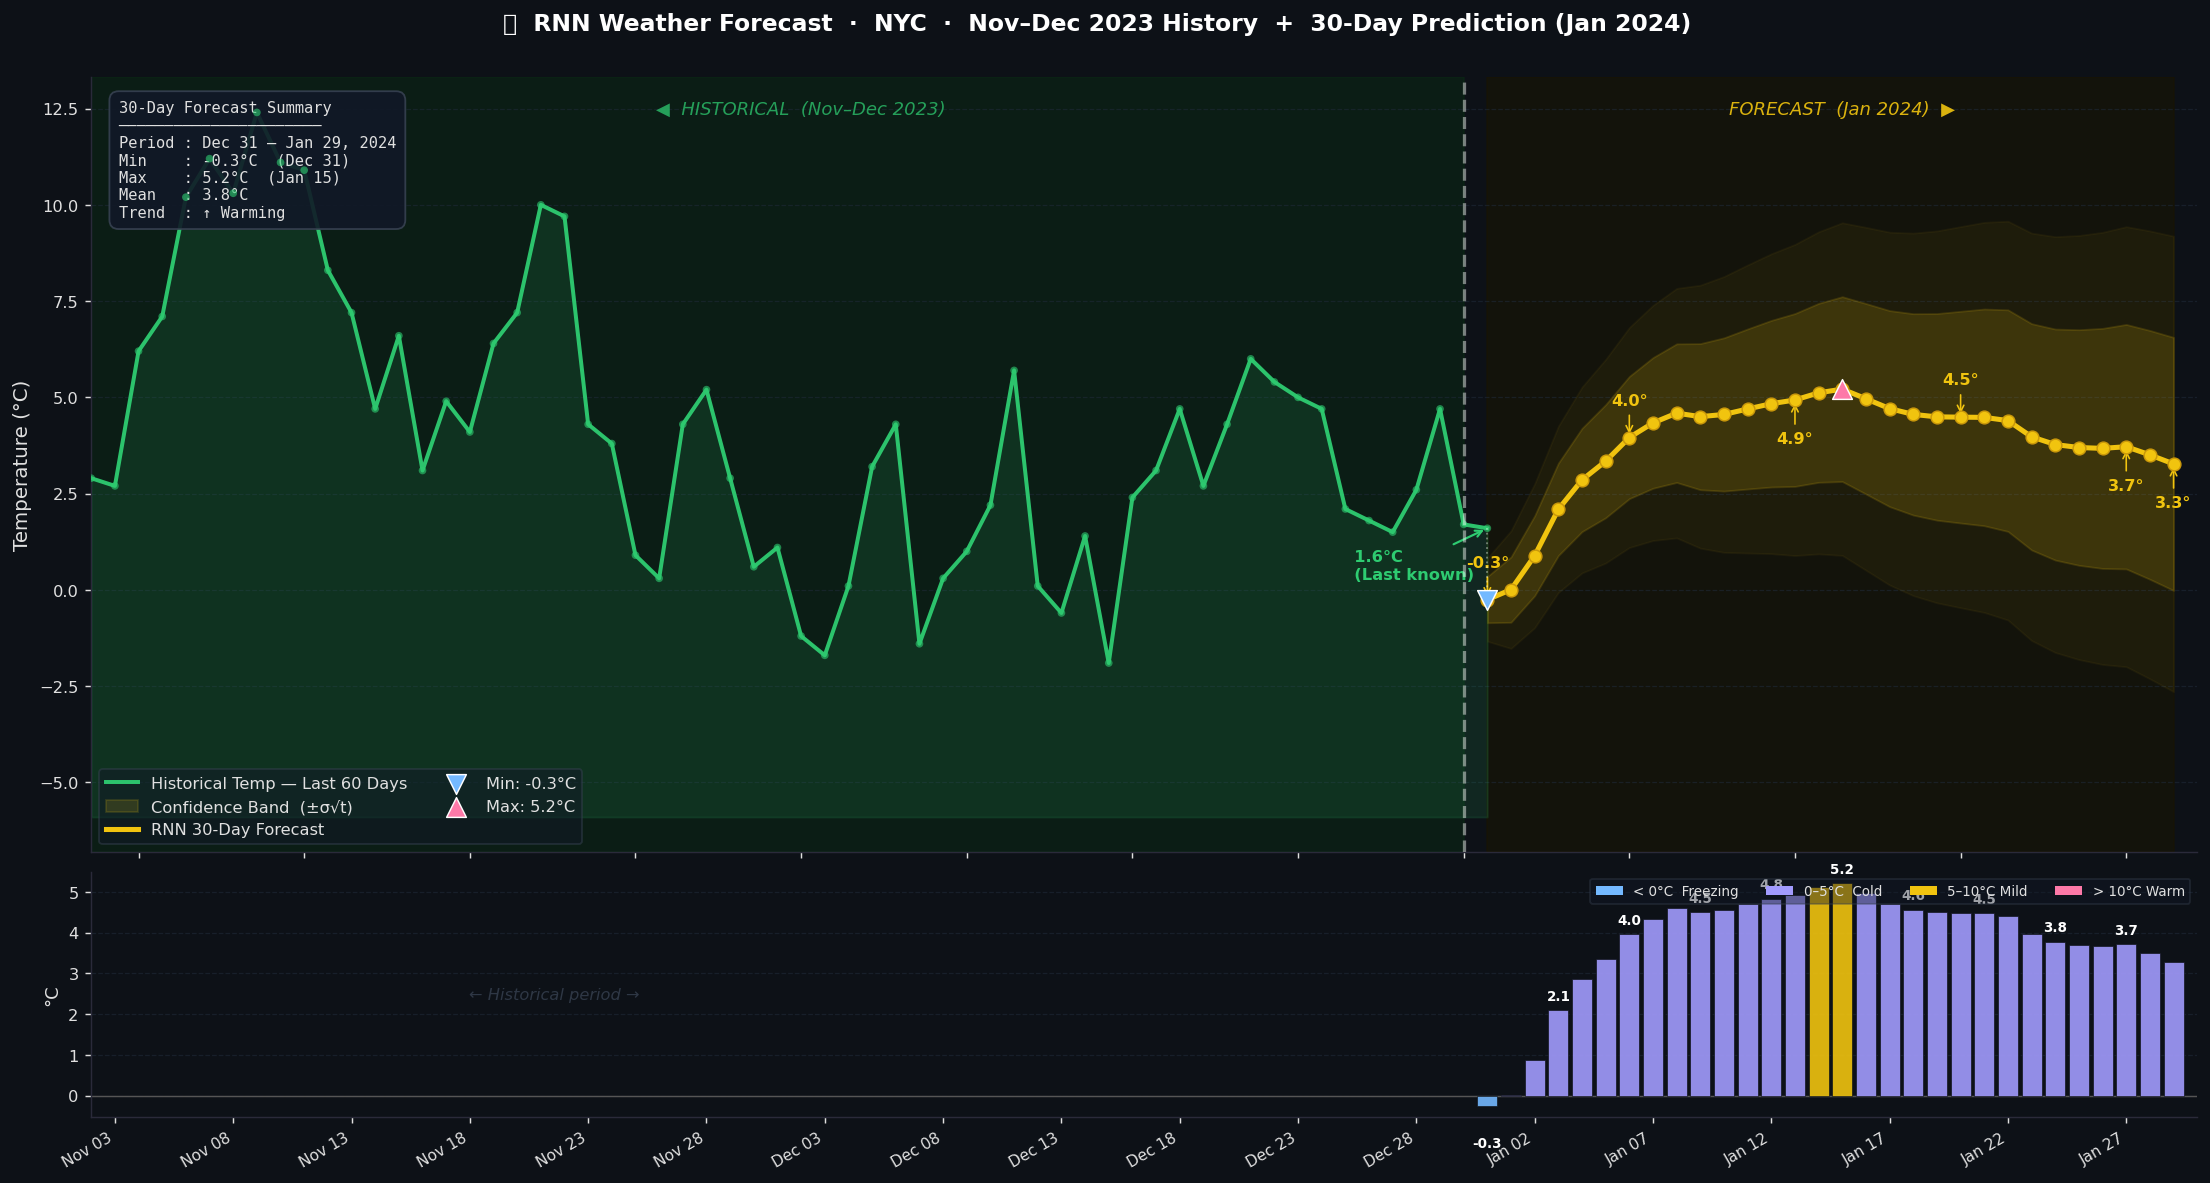

In [48]:
# ══════════════════════════════════════════════════════════════
#  Last 2 months history + 30-day forecast
# ══════════════════════════════════════════════════════════════

BG      = '#0d1117'
C_HIST  = '#2ecc71'   # green
C_PRED  = '#f1c40f'   # yellow
C_TEXT  = '#e0e0e0'
C_GRID  = '#1f2937'

# Slice: only last 60 days of history
hist_window  = 60
ctx_dates    = df.index[-hist_window:]
ctx_temps    = df['temp_mean'].values[-hist_window:]

# All dates for x-axis span
all_dates    = ctx_dates.append(future_dates)

fig = plt.figure(figsize=(18, 10), facecolor=BG)
gs  = GridSpec(4, 1, figure=fig,
               hspace=0.08, top=0.90, bottom=0.10,
               left=0.07, right=0.97)
ax_main = fig.add_subplot(gs[0:3, 0])
ax_bar  = fig.add_subplot(gs[3, 0])

for ax in [ax_main, ax_bar]:
    ax.set_facecolor(BG)
    ax.tick_params(colors=C_TEXT, labelsize=9)
    for spine in ax.spines.values():
        spine.set_edgecolor('#2a2a3a')
    ax.yaxis.grid(True, color=C_GRID, linestyle='--', alpha=0.6, linewidth=0.7)
    ax.xaxis.grid(False)
    ax.set_axisbelow(True)

# ─────────────────────────────────────────────────────────────
# MAIN PANEL
# ─────────────────────────────────────────────────────────────

# Shaded region backgrounds
ax_main.axvspan(ctx_dates[0], last_date,
                color='#0a2a14', alpha=0.5, zorder=0)
ax_main.axvspan(future_dates[0], future_dates[-1],
                color='#1a1500', alpha=0.5, zorder=0)

# ── GREEN: historical last 60 days ────────────────────────────
ax_main.fill_between(ctx_dates,
                     ctx_temps.min() - 4, ctx_temps,
                     color=C_HIST, alpha=0.12, zorder=1)
ax_main.plot(ctx_dates, ctx_temps,
             color=C_HIST, linewidth=2.2, zorder=3, alpha=0.95,
             label='Historical Temp — Last 60 Days')
ax_main.scatter(ctx_dates, ctx_temps,
                color=C_HIST, s=18, zorder=4,
                edgecolors='none', alpha=0.6)

# Annotate last historical point
ax_main.annotate(
    f'  {ctx_temps[-1]:.1f}°C\n  (Last known)',
    xy=(ctx_dates[-1], ctx_temps[-1]),
    fontsize=9, color=C_HIST, fontweight='bold',
    xytext=(-80, -28), textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color=C_HIST, lw=1.2)
)

# ── Divider ───────────────────────────────────────────────────
ax_main.axvline(x=last_date,
                color='#ffffff', linewidth=1.8,
                linestyle='--', alpha=0.45, zorder=5)

# Section labels at top
y_top = ax_main.get_ylim()[1] if ax_main.get_ylim()[1] != 0 else 15
mid_hist   = ctx_dates[len(ctx_dates)//2]
mid_future = future_dates[len(future_dates)//2]

ax_main.text(mid_hist,   0.97, '◀  HISTORICAL  (Nov–Dec 2023)',
             transform=ax_main.get_xaxis_transform(),
             ha='center', va='top', color=C_HIST,
             fontsize=10, alpha=0.75, fontstyle='italic')
ax_main.text(mid_future, 0.97, 'FORECAST  (Jan 2024)  ▶',
             transform=ax_main.get_xaxis_transform(),
             ha='center', va='top', color=C_PRED,
             fontsize=10, alpha=0.9, fontstyle='italic')

# ── YELLOW: confidence band ────────────────────────────────────
ax_main.fill_between(future_dates, lower, upper,
                     color=C_PRED, alpha=0.15, zorder=2,
                     label=f'Confidence Band  (±σ√t)')

# Outer wider band
ax_main.fill_between(future_dates,
                     future_temps - uncertainty*1.8,
                     future_temps + uncertainty*1.8,
                     color=C_PRED, alpha=0.05, zorder=1)

# ── YELLOW: forecast line ─────────────────────────────────────
ax_main.plot(future_dates, future_temps,
             color=C_PRED, linewidth=2.8, zorder=6, alpha=1.0,
             label='RNN 30-Day Forecast')
ax_main.scatter(future_dates, future_temps,
                color=C_PRED, s=50, zorder=7,
                edgecolors='#c9970a', linewidths=0.8)

# Bridge connector
ax_main.plot([ctx_dates[-1], future_dates[0]],
             [ctx_temps[-1], future_temps[0]],
             color='white', linewidth=1.0,
             linestyle=':', alpha=0.4, zorder=5)

# Annotate every 7th forecast day + min/max
for i in [0, 6, 13, 20, 27, 29]:
    offset = (0, 18) if i % 2 == 0 else (0, -24)
    ax_main.annotate(
        f'{future_temps[i]:.1f}°',
        xy=(future_dates[i], future_temps[i]),
        xytext=offset, textcoords='offset points',
        ha='center', color=C_PRED, fontsize=9, fontweight='bold',
        arrowprops=dict(arrowstyle='->', color=C_PRED, lw=0.9)
    )

# Min/Max markers
imin = np.argmin(future_temps); imax = np.argmax(future_temps)
ax_main.scatter([future_dates[imin]], [future_temps[imin]],
                color='#74b9ff', s=120, zorder=8, marker='v',
                edgecolors='white', linewidths=0.8, label=f'Min: {future_temps[imin]:.1f}°C')
ax_main.scatter([future_dates[imax]], [future_temps[imax]],
                color='#fd79a8', s=120, zorder=8, marker='^',
                edgecolors='white', linewidths=0.8, label=f'Max: {future_temps[imax]:.1f}°C')

# ── Stats box ─────────────────────────────────────────────────
stats_txt = (
    f'30-Day Forecast Summary\n'
    f'──────────────────────\n'
    f'Period : {future_dates[0].strftime("%b %d")} – {future_dates[-1].strftime("%b %d, %Y")}\n'
    f'Min    : {future_temps.min():.1f}°C  ({future_dates[imin].strftime("%b %d")})\n'
    f'Max    : {future_temps.max():.1f}°C  ({future_dates[imax].strftime("%b %d")})\n'
    f'Mean   : {future_temps.mean():.1f}°C\n'
    f'Trend  : {"↓ Cooling" if future_temps[-7:].mean() < future_temps[:7].mean() else "↑ Warming"}'
)
ax_main.text(0.013, 0.97, stats_txt,
             transform=ax_main.transAxes,
             fontsize=8.5, va='top', ha='left',
             color=C_TEXT, family='monospace',
             bbox=dict(boxstyle='round,pad=0.6',
                       facecolor='#111827',
                       edgecolor='#374151', alpha=0.9))

# Formatting
ax_main.set_xlim(ctx_dates[0], future_dates[-1] + pd.Timedelta(days=1))
ax_main.set_ylabel('Temperature (°C)', color=C_TEXT, fontsize=11)
ax_main.yaxis.set_tick_params(labelcolor=C_TEXT)
ax_main.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax_main.xaxis.set_major_locator(mdates.DayLocator(interval=7))
plt.setp(ax_main.get_xticklabels(), visible=False)

leg = ax_main.legend(
    loc='lower left', ncol=2,
    framealpha=0.5, facecolor='#111827',
    edgecolor='#374151', labelcolor=C_TEXT, fontsize=9
)

fig.suptitle(
    '🌡  RNN Weather Forecast  ·  NYC  ·  Nov–Dec 2023 History  +  30-Day Prediction (Jan 2024)',
    color='white', fontsize=13, fontweight='bold', y=0.95
)

# Color bars by temperature
bar_colors_arr = []
for t in future_temps:
    if t < 0:   bar_colors_arr.append('#74b9ff')   # freezing → blue
    elif t < 5: bar_colors_arr.append('#a29bfe')   # cold → purple
    elif t < 10:bar_colors_arr.append(C_PRED)      # mild → yellow
    else:       bar_colors_arr.append('#fd79a8')   # warm → pink

ax_bar.set_xlim(ctx_dates[0], future_dates[-1] + pd.Timedelta(days=1))

# Fill the history side of bar panel with nothing (blank)
ax_bar.axvspan(ctx_dates[0], last_date,
               color='#0d1117', alpha=1.0, zorder=0)
ax_bar.text(0.22, 0.5, '← Historical period →',
            transform=ax_bar.transAxes,
            ha='center', va='center', color='#374151',
            fontsize=9, fontstyle='italic', alpha=0.8)

# Bars — only future_dates
bars = ax_bar.bar(
    future_dates, future_temps,
    color=bar_colors_arr, alpha=0.90,
    width=0.85, zorder=3, edgecolor='#0d1117', linewidth=0.4
)
ax_bar.axhline(0, color='#555', linewidth=0.8, zorder=2)

# Label every bar
for i, (bar, t) in enumerate(zip(bars, future_temps)):
    if i % 3 == 0:   # label every 3rd to avoid clutter
        y_off = bar.get_height() + 0.25 if t >= 0 else bar.get_height() - 1.0
        ax_bar.text(
            bar.get_x() + bar.get_width()/2, y_off,
            f'{t:.1f}', ha='center', fontsize=7.5,
            color='white', fontweight='bold', zorder=5
        )

ax_bar.set_ylabel('°C', color=C_TEXT, fontsize=10)
ax_bar.yaxis.set_tick_params(labelcolor=C_TEXT)
ax_bar.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax_bar.xaxis.set_major_locator(mdates.DayLocator(interval=5))
plt.setp(ax_bar.get_xticklabels(), rotation=30, ha='right',
         color=C_TEXT, fontsize=8.5)

# Color legend for bars
from matplotlib.patches import Patch
bar_legend = [
    Patch(facecolor='#74b9ff', label='< 0°C  Freezing'),
    Patch(facecolor='#a29bfe', label='0–5°C  Cold'),
    Patch(facecolor=C_PRED,    label='5–10°C Mild'),
    Patch(facecolor='#fd79a8', label='> 10°C Warm'),
]
ax_bar.legend(handles=bar_legend, loc='upper right',
              ncol=4, fontsize=7.5, framealpha=0.4,
              facecolor='#111827', edgecolor='#374151',
              labelcolor=C_TEXT)

plt.show()

In [44]:
# ── Forecast table ────────────────────────────────────────────
forecast_df = pd.DataFrame({
    'Date'        : future_dates.strftime('%Y-%m-%d'),
    'Weekday'     : future_dates.strftime('%a'),
    'Forecast°C'  : np.round(future_temps, 2),
    'Lower°C'     : np.round(lower, 2),
    'Upper°C'     : np.round(upper, 2),
})

forecast_df.style \
    .set_caption('RNN — 30-Day Temperature Forecast') \
    .background_gradient(subset=['Forecast°C'], cmap='RdYlGn') \
    .format({'Forecast°C':'{:.2f}','Lower°C':'{:.2f}','Upper°C':'{:.2f}'})

,Date,Weekday,Forecast°C,Lower°C,Upper°C
0,2023-12-31,Sun,-0.25,-0.85,0.35
1,2024-01-01,Mon,0.01,-0.84,0.86
2,2024-01-02,Tue,0.89,-0.15,1.93
3,2024-01-03,Wed,2.09,0.89,3.29
4,2024-01-04,Thu,2.85,1.51,4.20
5,2024-01-05,Fri,3.34,1.87,4.81
6,2024-01-06,Sat,3.96,2.37,5.54
7,2024-01-07,Sun,4.34,2.64,6.03
8,2024-01-08,Mon,4.59,2.79,6.39
9,2024-01-09,Tue,4.50,2.60,6.40
